In [1]:
import pandas as pd
import scanpy as sc
import numpy as np
import anndata as ad
import os
import colorcet as cc
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import harmonypy as hm
import scrublet as scr
import traceback
from collections import Counter
from sklearn.decomposition import PCA
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import re
from matplotlib.patches import Patch
from PIL import Image

# --- ADOBE ILLUSTRATOR COMPATIBILITY ---
# 42 is for TrueType fonts (editable text in Illustrator)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
sc.settings.set_figure_params(dpi=300, dpi_save=300)



# --- NOTEBOOK SETTINGS ---
%matplotlib inline

# Define Working Directory
working_dic = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/"
os.chdir(working_dic)

# --- SCANPY SETTINGS ---
sc.settings.verbosity = 1
sc.logging.print_header()

# Professional Plotting Parameters
# sc.set_figure_params( dpi=100,  dpi_save=300,  vector_friendly=True, format='pdf',  transparent=True, facecolor='white' )

# --- CUSTOM COLOR SCHEMES ---
# Your grey-to-blue gradient for feature plots
dimplot_color = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["#E5E5E5", "#4C4DB7"])

COND_ORDER = [
    "Control",
    "Prematurely-terminated",
    "3month-protocol",
    "6month-protocol",
    "PCMV/PRV",
    "Rejection",
]

COND_COLORS = {
    "Control": "#EFE48E",
    "3month-protocol": "skyblue",
    "6month-protocol": "#08528f",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}


In [2]:
raw_myeloids = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v2/objects/very_cleaned_raw_Mye_sus_v2.h5ad')

Loaded: 2,856 nuclei  ×  53,826 genes
Conditions: {'Prematurely-terminated': 1678, 'Control': 470, 'Rejection': 397, 'PCMV/PRV': 282, '3month-protocol': 21, '6month-protocol': 8}


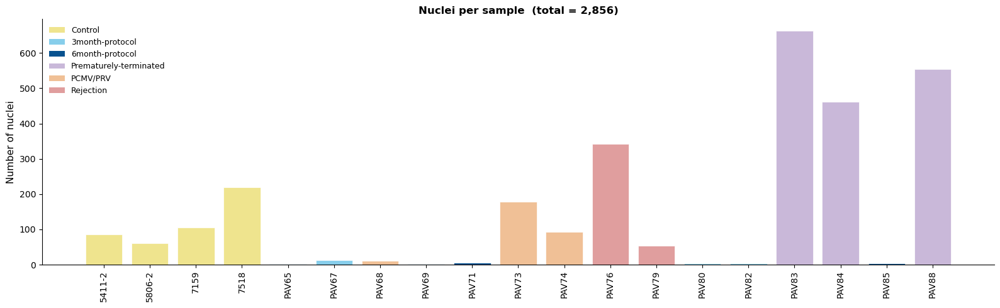

In [5]:
 
raw_myeloids = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v2/objects/very_cleaned_raw_Mye_sus_v2.h5ad')

adata = raw_myeloids.copy()
 
print(f"Loaded: {adata.n_obs:,} nuclei  ×  {adata.n_vars:,} genes")
print(f"Conditions: {adata.obs['Condition'].value_counts().to_dict()}")
 
# Cell count bar plot per sample
sample_meta = adata.obs[["Sample_ID", "Condition"]].drop_duplicates().set_index("Sample_ID")
counts      = adata.obs["Sample_ID"].value_counts().sort_index()
bar_colors  = [COND_COLORS.get(sample_meta.loc[s, "Condition"], "grey") for s in counts.index]
 
fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(range(len(counts)), counts.values, color=bar_colors, edgecolor="white", linewidth=0.5)
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=90, fontsize=10)
ax.set_ylabel("Number of nuclei", fontsize=11)
ax.set_title(f"Nuclei per sample  (total = {adata.n_obs:,})", fontsize=12, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    handles=[Patch(facecolor=v, label=k) for k, v in COND_COLORS.items()],
    loc="upper left", frameon=False, fontsize=9
)
plt.tight_layout()
# plt.savefig(f"{OUTPUT_DIR}/01_cell_counts_per_sample.pdf", dpi=150, bbox_inches="tight")
plt.show()
# print("Saved: 01_cell_counts_per_sample")



In [6]:
counts

Sample_ID
5411-2     86
5806-2     60
7159      105
7518      219
PAV65       1
PAV67      12
PAV68      11
PAV69       2
PAV71       5
PAV73     179
PAV74      92
PAV76     343
PAV79      54
PAV80       3
PAV82       3
PAV83     663
PAV84     461
PAV85       3
PAV88     554
Name: count, dtype: int64

# preprocessing

In [2]:
raw_myeloids = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v2/objects/very_cleaned_raw_Mye_sus_v2.h5ad')

adata = raw_myeloids.copy()
 
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
 
# Store normalised + log-transformed counts for all genes.
# .raw is used later for differential expression (all genes, not just HVGs).
adata.raw = adata.copy()
print(f".raw stored: {adata.raw.shape[0]:,} nuclei × {adata.raw.shape[1]:,} genes")


.raw stored: 2,856 nuclei × 53,826 genes


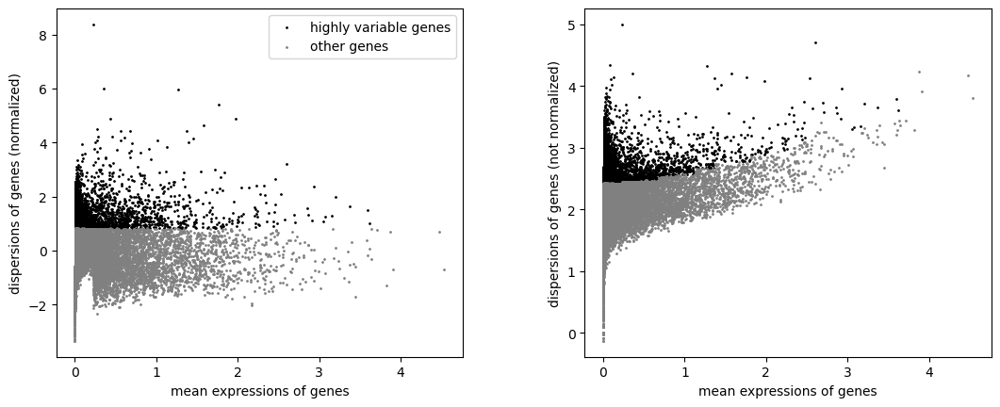

Number of highly variable genes (HVGs): 4003
Subsetting complete. New shape: (2856, 4003)


In [3]:
# 1. Identify highly variable genes 

sc.pp.highly_variable_genes(
    adata, 
    n_top_genes=4000, 
    subset=False, 
    flavor='seurat'
)

# 2. Plot highly variable genes
# This will highlight the top 5000 in red
sc.pl.highly_variable_genes(adata)

# 3. Verify the count
num_hvgs = adata.var['highly_variable'].sum()
print(f"Number of highly variable genes (HVGs): {num_hvgs}")

# 4. Subset to HVGs for downstream analysis (PCA/Harmony)
# We keep a copy of the full object if needed, but subset for speed
adata_hvg = adata[:, adata.var['highly_variable']].copy()

print(f"Subsetting complete. New shape: {adata_hvg.shape}")


Using 13 samples for HVG calculation.


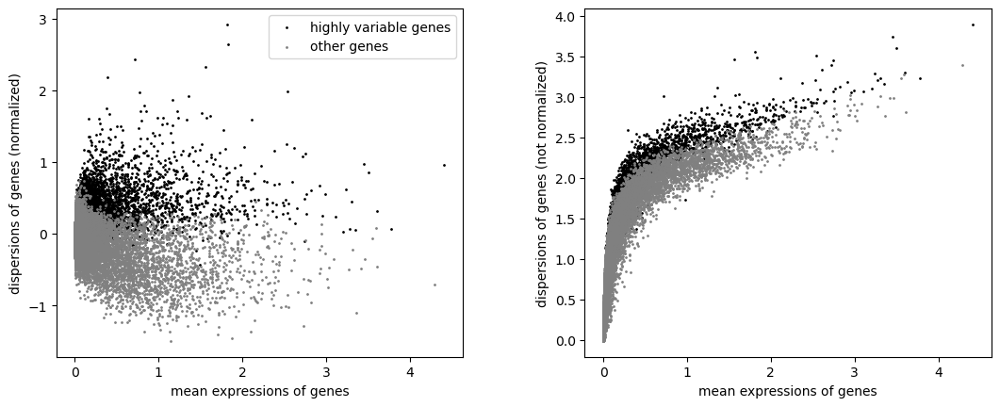

Number of HVGs selected: 3000


In [3]:
# # 1. Determine which samples are "stable" (e.g., at least 10 Myeloid cells)
# MIN_CELLS = 10
# batch_counts = adata.obs['Sample_ID'].value_counts()
# stable_batches = batch_counts[batch_counts >= MIN_CELLS].index.tolist()

# print(f"Using {len(stable_batches)} samples for HVG calculation.")

# # =================================================================
# # FIX 1: Actually subset the adata to KEEP ONLY the stable batches
# adata = adata[adata.obs['Sample_ID'].isin(stable_batches)].copy()

# # FIX 2: Clean up the categorical metadata! 
# # If we don't drop unused categories, Scanpy still tries to process them.
# if adata.obs['Sample_ID'].dtype.name == 'category':
#     adata.obs['Sample_ID'] = adata.obs['Sample_ID'].cat.remove_unused_categories()
# # =================================================================

# # 2. Run HVG selection
# # We use flavor='seurat' because you have already normalized/log-transformed.
# sc.pp.highly_variable_genes(
#     adata,
#     batch_key='Sample_ID',
#     n_top_genes=3000,
#     flavor='seurat',
#     subset=False  # We don't subset yet so we don't lose the .raw data
# )

# sc.pl.highly_variable_genes(adata, show=False)
# plt.show()

# # 4. Check how many HVGs were found
# n_hvg = adata.var['highly_variable'].sum()
# print(f"Number of HVGs selected: {n_hvg}")

# # 5. Subset to HVGs for dimensionality reduction
# adata_hvg = adata[:, adata.var.highly_variable].copy()


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


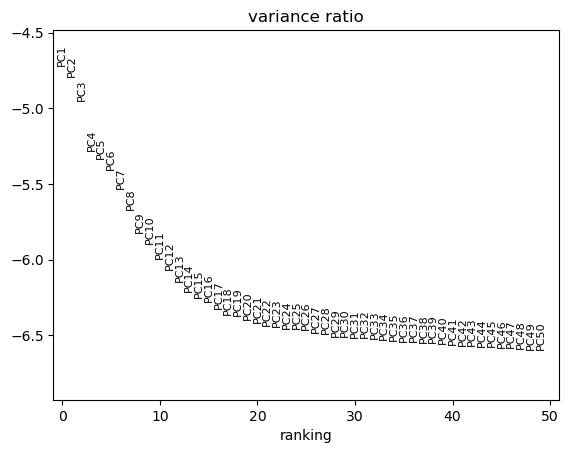

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [4]:
# 2. Scale the data (z-score normalization)
sc.pp.scale(adata_hvg, max_value=10)  # max_value=10 clips extreme outliers

# 3. Run PCA
sc.tl.pca(adata_hvg, n_comps=50, svd_solver='arpack')  # Adjust n_comps as needed

# 4. (Optional) Plot variance explained
sc.pl.pca_variance_ratio(adata_hvg, log=True, n_pcs=50)

adata_hvg.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Mye_sus_hvg_xeno_v3.h5ad')


In [5]:
pca_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Mye_sus_hvg_xeno_v3.h5ad')


# Harmony

In [64]:
pca_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Mye_sus_hvg_xeno_v3.h5ad')


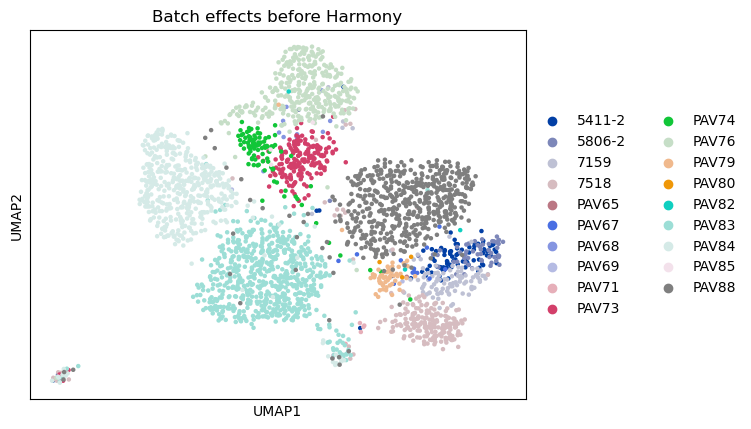

In [65]:
# Checking batch effects before Harmony
sc.pp.neighbors(pca_adata, random_state=10, n_neighbors=20, n_pcs=40)

# Perform UMAP
sc.tl.umap(pca_adata)

# Plot UMAP colored by sample (batch) and save it
sc.pl.umap (pca_adata, color=['Sample_ID'],  title='Batch effects before Harmony')

In [66]:
# Subset PCA to exactly the PCs used for neighbours
pca_matrix = pca_adata.obsm["X_pca"][:, :40].copy()
print(f"PCA matrix passed to Harmony: {pca_matrix.shape}")

ho = hm.run_harmony(
    pca_matrix,
    pca_adata.obs,
    vars_use="Sample_ID",
    # max_iter_harmony=20,
    epsilon_harmony=-float('Inf'), # FORCE RUN: Ignore early convergence
    epsilon_cluster=-float('Inf'), # FORCE RUN: Ignore early convergence
    
    random_state=10,
    verbose=True         # Prints iteration + objective value so you can
                         # see exactly when and why it stops
)
 
pca_adata.obsm["X_pca_harmony"] = ho.Z_corr.T
 
print(f"\nHarmony embedding stored in obsm['X_pca_harmony']")
print(f"Shape: {pca_adata.obsm['X_pca_harmony'].shape}") 
 

2026-06-22 15:59:28,924 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...


PCA matrix passed to Harmony: (2856, 40)


2026-06-22 15:59:29,430 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-06-22 15:59:29,450 - harmonypy - INFO - Iteration 1 of 10
2026-06-22 15:59:29,929 - harmonypy - INFO - Iteration 2 of 10
2026-06-22 15:59:30,402 - harmonypy - INFO - Iteration 3 of 10
2026-06-22 15:59:30,879 - harmonypy - INFO - Iteration 4 of 10
2026-06-22 15:59:31,354 - harmonypy - INFO - Iteration 5 of 10
2026-06-22 15:59:31,829 - harmonypy - INFO - Iteration 6 of 10
2026-06-22 15:59:32,302 - harmonypy - INFO - Iteration 7 of 10
2026-06-22 15:59:32,778 - harmonypy - INFO - Iteration 8 of 10
2026-06-22 15:59:33,251 - harmonypy - INFO - Iteration 9 of 10
2026-06-22 15:59:33,728 - harmonypy - INFO - Iteration 10 of 10
2026-06-22 15:59:34,207 - harmonypy - INFO - Stopped before convergence



Harmony embedding stored in obsm['X_pca_harmony']
Shape: (2856, 40)


In [67]:
pca_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/HM_Mye_sus_xeno_v3.h5ad')


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [68]:
hm_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/HM_Mye_sus_xeno_v3.h5ad')


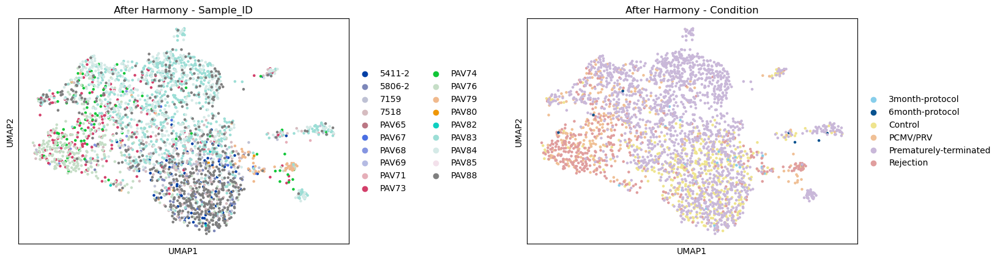

In [54]:
# Compute neighbors using Harmony embeddings
sc.pp.neighbors(
    hm_adata, 
    use_rep='X_pca_harmony',  # This is the key - use Harmony instead of PCA
    n_neighbors=20, 
    n_pcs=35,
    random_state=10
)

# Recompute UMAP based on Harmony
sc.tl.umap(hm_adata, random_state=10)

# Visualize - should show reduced batch effects
sc.pl.umap(
    hm_adata, color=['Sample_ID', 'Condition'],  ncols=2, wspace = 0.4,  title=['After Harmony - Sample_ID', 'After Harmony - Condition']
)

In [12]:
# 1. Compute Neighbors (Graph building)
sc.pp.neighbors(
    hm_adata, 
    use_rep='X_pca_harmony', 
    n_neighbors=20, 
    n_pcs=40,
    random_state=10
)

# 2. Run UMAP with min_dist and spread (Embedding/Visualization)
sc.tl.umap(
    hm_adata, 
    min_dist=0.5, 
    spread=0.5, 
    random_state=10
)

# 3. Run Leiden Clustering (Community detection)
resolutions = [
    0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4
              ]

for res in resolutions:
    # Formats key cleanly (e.g., leiden_03, leiden_04)
    key = f"leiden_{str(res).replace('.', '')}"
    print(f"Running Leiden clustering at resolution {res} -> stored in {key}")
    
    sc.tl.leiden(
        hm_adata, 
        resolution=res, 
        key_added=key, 
        random_state=10
    )

print("✓ UMAP and Leiden clustering complete.")

Running Leiden clustering at resolution 0.3 -> stored in leiden_03
Running Leiden clustering at resolution 0.4 -> stored in leiden_04


/tmp/ipykernel_1684880/738879549.py:28: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


Running Leiden clustering at resolution 0.5 -> stored in leiden_05
Running Leiden clustering at resolution 0.6 -> stored in leiden_06
Running Leiden clustering at resolution 0.7 -> stored in leiden_07
Running Leiden clustering at resolution 0.8 -> stored in leiden_08
Running Leiden clustering at resolution 0.9 -> stored in leiden_09
Running Leiden clustering at resolution 1.0 -> stored in leiden_10
Running Leiden clustering at resolution 1.1 -> stored in leiden_11
Running Leiden clustering at resolution 1.2 -> stored in leiden_12
Running Leiden clustering at resolution 1.3 -> stored in leiden_13
Running Leiden clustering at resolution 1.4 -> stored in leiden_14
✓ UMAP and Leiden clustering complete.


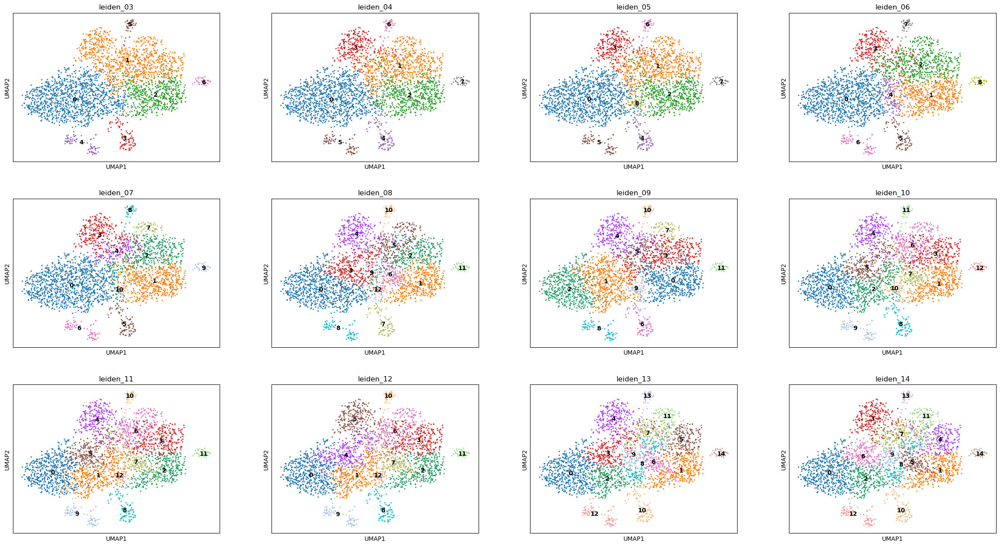

In [13]:

sc.pl.umap( hm_adata, color=[  "leiden_03", "leiden_04", "leiden_05" , "leiden_06" , "leiden_07", "leiden_08" , "leiden_09", "leiden_10", "leiden_11", "leiden_12", "leiden_13", "leiden_14" ],
            legend_loc="on data",  size=20)


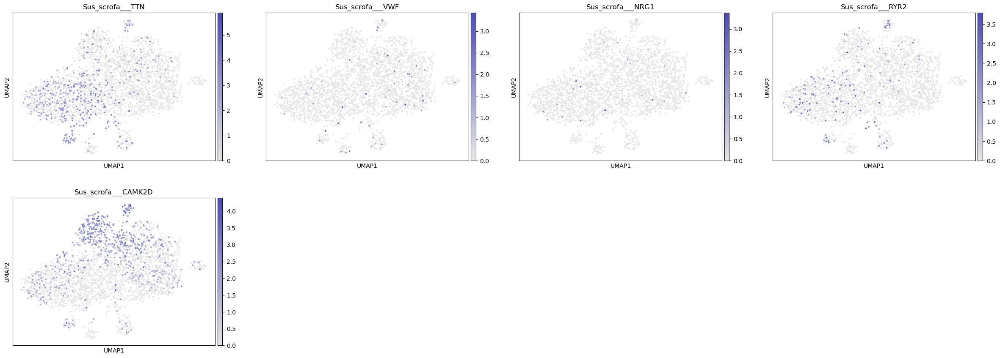

In [14]:

sc.pl.umap( hm_adata, color=[ 
    # "leiden_03", "leiden_04", "leiden_05" , "leiden_06" , "leiden_07", "leiden_08" , "leiden_09", "leiden_10", "leiden_11", "leiden_12", "leiden_13", "leiden_14" 
#                             'Sus_scrofa___VCAN', 'Sus_scrofa___SPP1','Sus_scrofa___TREM2', 'Sus_scrofa___APOE',  'Sus_scrofa___LPL',  
# 'Sus_scrofa___GPNMB', 'Sus_scrofa___FABP5',  

        'Sus_scrofa___TTN', 
        'Sus_scrofa___VWF', 'Sus_scrofa___NRG1', 'Sus_scrofa___RYR2', 'Sus_scrofa___CAMK2D', 
    
                            ], cmap = dimplot_color,
            legend_loc="on data",  size=30)


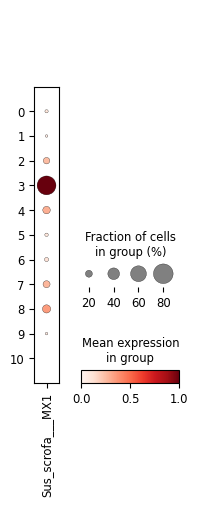

In [45]:
sc.pl.dotplot(
    hm_adata, 
    var_names=[

# 'Sus_scrofa___FN1', 
        'Sus_scrofa___MX1', 
        # 'Sus_scrofa___VWF', 'Sus_scrofa___NRG1', 'Sus_scrofa___RYR2', 'Sus_scrofa___CAMK2D', 
         # 'Sus_scrofa___APOE',  'Sus_scrofa___LPL',   'Sus_scrofa___TREM2', 
        # 'Sus_scrofa___SPP1', 
# 'Sus_scrofa___GPNMB', 'Sus_scrofa___FABP5',


        
    ], 
    groupby='leiden_07', 
    # standard_scale='var',  # Scales expression from 0 to 1 for better comparison
    cmap='Reds', 
    standard_scale = 'var',
    # use_raw = True

)
    

# DEA

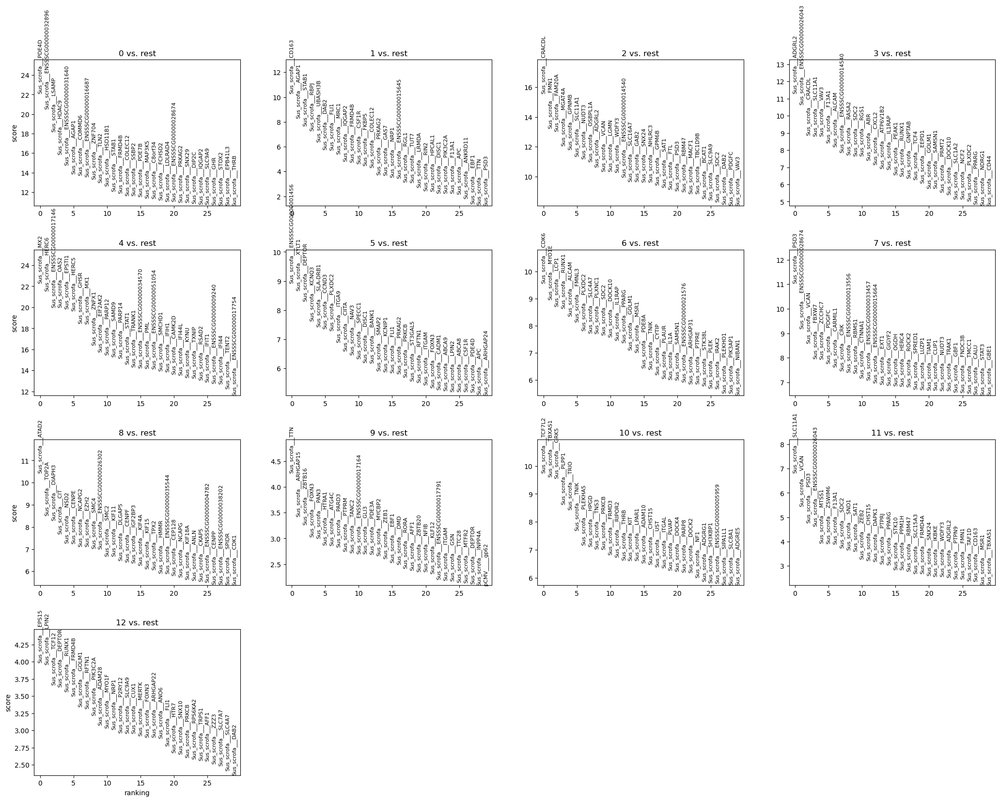

/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [16]:
# Perform differential expression to find marker genes for each cluster using Wilcoxon test on raw data
sc.tl.rank_genes_groups(hm_adata, 'leiden_11', method='wilcoxon', key_added='wilcoxon', use_raw=True)

# Visualize the top marker genes for each cluster
sc.pl.rank_genes_groups(hm_adata, key='wilcoxon', n_genes=30, sharey=False)

hm_adata.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/dea_mye_sus_xeno_v3.h5ad')


In [17]:
dea_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/dea_mye_sus_xeno_v3.h5ad')


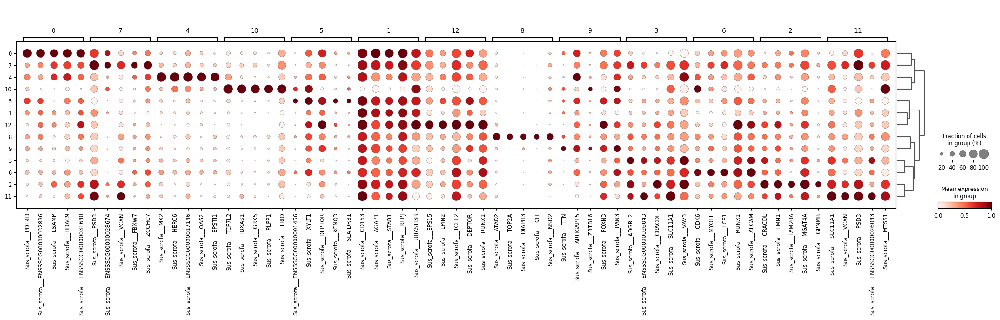

In [18]:
%matplotlib inline

sc.pl.rank_genes_groups_dotplot(dea_adata, key="wilcoxon", n_genes=5, standard_scale="var"
                                # , cmap="coolwarm", vmin= -1
                               )


In [20]:
import pandas as pd
import os

de_key = 'wilcoxon'  # The key you used in rank_genes_groups
results = dea_adata.uns[de_key]
clusters = results['names'].dtype.names  # These are your clusters

output_dir = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/DEGs'
os.makedirs(output_dir, exist_ok=True)

for clust in clusters:
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    # Optional: Sort by Wilcoxon score, descending (highest first)
    df = df.sort_values('score', ascending=False)
    # Save to CSV
    df.to_csv(f"{output_dir}/Cluster_{clust}_DEGs.csv", index=False)



In [58]:
import os
import pandas as pd

# 1. Setup paths
base_results_dir = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/DEGs'
sig_output_dir = os.path.join(base_results_dir, "significant_DEGs")
os.makedirs(sig_output_dir, exist_ok=True)

# 2. Thresholds
P_ADJ_CUTOFF = 0.05
LFC_CUTOFF = 0.5

print(f"Filtering DEGs: pval_adj < {P_ADJ_CUTOFF} and |logfoldchange| > {LFC_CUTOFF}")

# 3. Process each cluster's results from your previous loop
# Using the 'clusters' variable from your previous code block
for clust in clusters:
    # Extract data from the scanpy results object
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    # Create the DataFrame
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    
    # 4. Apply strict filtering
    # Filtering for p-adj AND (|LFC| > 0.75)
    sig_df = df[
        (df['pval_adj'] < P_ADJ_CUTOFF) & 
        ((df['logfoldchange'] > LFC_CUTOFF) | (df['logfoldchange'] < -LFC_CUTOFF))
    ].copy()
    
    # Sort by logfoldchange descending
    sig_df = sig_df.sort_values('logfoldchange', ascending=False)
    
    # 5. Save if there are significant genes found
    if not sig_df.empty:
        output_file = f"{sig_output_dir}/Significant_Cluster_{clust}_DEGs.csv"
        sig_df.to_csv(output_file, index=False)
        print(f"  Cluster {clust}: Saved {len(sig_df)} significant DEGs.")
    else:
        print(f"  Cluster {clust}: No genes met the significance criteria.")

print("\nAll significant files saved in:", sig_output_dir)

Filtering DEGs: pval_adj < 0.05 and |logfoldchange| > 0.5
  Cluster 0: Saved 671 significant DEGs.
  Cluster 1: Saved 1999 significant DEGs.
  Cluster 2: Saved 277 significant DEGs.
  Cluster 3: Saved 227 significant DEGs.
  Cluster 4: Saved 496 significant DEGs.
  Cluster 5: Saved 81 significant DEGs.
  Cluster 6: Saved 143 significant DEGs.
  Cluster 7: Saved 799 significant DEGs.
  Cluster 8: Saved 61 significant DEGs.
  Cluster 9: No genes met the significance criteria.
  Cluster 10: Saved 163 significant DEGs.
  Cluster 11: Saved 4 significant DEGs.
  Cluster 12: No genes met the significance criteria.

All significant files saved in: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/DEGs/significant_DEGs


In [2]:

sc.pl.umap( hm_adata, color=[ "leiden_11", 'pCMV_____gp07'], cmap = dimplot_color,
            legend_loc="on data",  size=20)


NameError: name 'hm_adata' is not defined

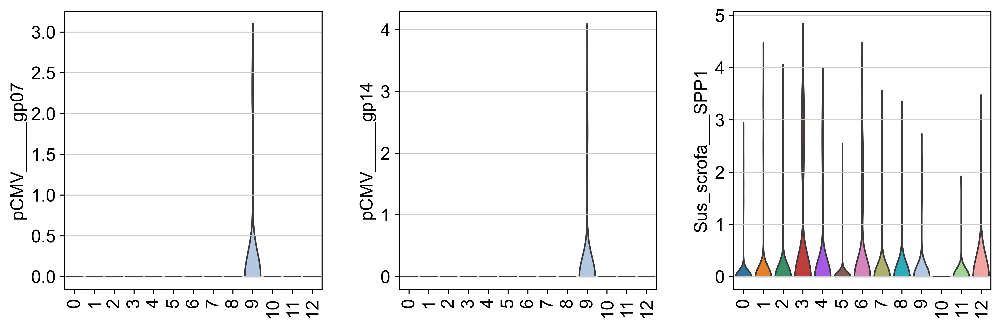

In [87]:
cluster_key = 'leiden_11'        # or 'FB_clusters' or whatever you used

qc_vars = ['pCMV_____gp07', 'pCMV_____gp14', "Sus_scrofa___SPP1"
           # 'total_counts', 'percent_mito', 'doublet_score'
          ]

sc.pl.violin(
    dea_adata,
    qc_vars,
    groupby=cluster_key,
    rotation=90,
    stripplot=False,
    multi_panel=True
)


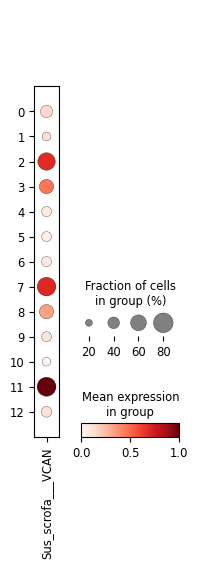

In [65]:
sc.pl.dotplot(
    dea_adata, 
    var_names=[

# 'Sus_scrofa___FN1', 
        # 'Sus_scrofa___LYVE1', 
        'Sus_scrofa___VCAN', 
 #         'Sus_scrofa___APOE',  'Sus_scrofa___LPL',  
 #        'Sus_scrofa___TREM2', 
 #        'Sus_scrofa___SPP1', 
 # 'Sus_scrofa___FABP5',

 # 'Sus_scrofa___SLA-DRB1', 'Sus_scrofa___CIITA', 'Sus_scrofa___SLA-DQB1'
        
    ], 
    groupby='leiden_11', 
    # standard_scale='var',  # Scales expression from 0 to 1 for better comparison
    cmap='Reds', 
    standard_scale = 'var',
    # use_raw = True

)
    

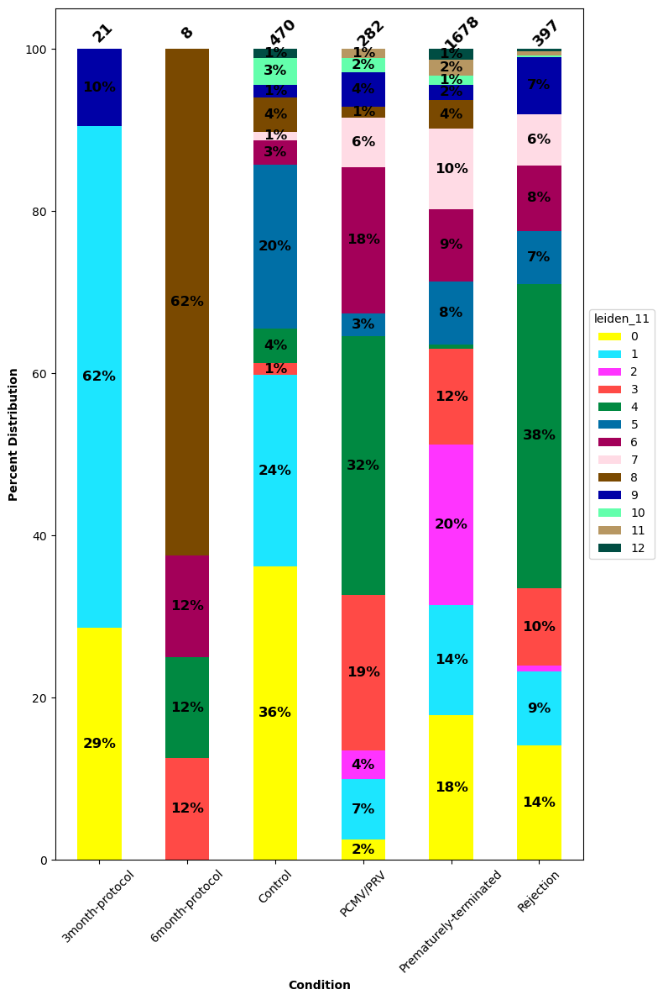

In [54]:
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

def stacked_barplot(adata, xaxis, stack, xaxis_label, legend_label, shift_top=0.2, xaxis_rotation=45, figsize=(10,10), percent=True):
    
    # Calculate absolute counts and percentages
    tmp = pd.crosstab(adata.obs[xaxis], adata.obs[stack]).sum(axis=1)
    ax = pd.crosstab(adata.obs[xaxis], adata.obs[stack]).apply(lambda r: r/r.sum()*100, axis=1)
    
    # Hijack Scanpy's default 102-color palette for highly distinct cluster colors
    large_palette = sc.pl.palettes.default_102
    
    # Plot using the custom large palette
    ax_1 = ax.plot.bar(figsize=figsize, stacked=True, rot=0, color=large_palette)
    
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title=legend_label)
    plt.xlabel(xaxis_label, fontweight="bold")
    plt.ylabel('Percent Distribution', fontweight="bold")
    
    # Add percentage labels inside bars
    if percent:
        for rec in ax_1.patches:
            height = rec.get_height()
            # Only label bars larger than 1% to avoid massive overlapping text clutter
            if height > 1: 
                ax_1.text(rec.get_x() + rec.get_width() / 2, 
                          rec.get_y() + height / 2, 
                          "{:.0f}%".format(height),
                          ha='center', va='center', fontsize=12, weight='bold')
    
    # Add total cell counts at the top of each bar
    for xaxistick in range(ax.shape[0]):
        ax_1.text(xaxistick - shift_top, 
                  102, # Placed slightly above 100%
                  int(tmp.iloc[xaxistick]), 
                  va='center', rotation=45, fontsize=13, weight='bold')
    
    plt.xticks(rotation=xaxis_rotation)
    ax_1.grid(False)
    
    # Adjust layout to make room for the legend outside the plot
    plt.tight_layout()
    plt.show()

# Run the function
stacked_barplot(
    dea_adata, 
    'Condition', 
    'leiden_11', 
    'Condition', 
    'leiden_11', 
    shift_top=0.1, 
    xaxis_rotation=45, 
    figsize=(8, 12), 
    percent=True
)

In [64]:
import os
import scanpy as sc
import pandas as pd
import numpy as np

# 1. Define cluster details
cluster_id = '11'
cluster_col = 'leiden_11' 
output_dir = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects'
output_csv = os.path.join(output_dir, f'top_100_expressed_genes_cluster_{cluster_id}.csv')

# 2. Subset the data
# We check if it is a sparse matrix; if so, we convert it to dense to calculate the mean
if dea_adata.raw is not None:
    adata_cluster = dea_adata[dea_adata.obs[cluster_col] == cluster_id].raw.to_adata()
else:
    adata_cluster = dea_adata[dea_adata.obs[cluster_col] == cluster_id].copy()

# 3. Calculate mean expression
# .X might be a sparse matrix, so we use .A if it's sparse to convert to dense
# .mean(axis=0) creates a 1D array of shape (n_genes,)
if hasattr(adata_cluster.X, "A"):
    mean_vals = adata_cluster.X.A.mean(axis=0)
else:
    mean_vals = adata_cluster.X.mean(axis=0)

# FIX: Explicitly reshape to (n_genes, 1) to match index size (53826, 1)
mean_expression = pd.DataFrame(
    mean_vals.reshape(-1, 1), 
    index=adata_cluster.var_names, 
    columns=['mean_expression']
)

# 4. Sort and get top 100
top_100_expressed = mean_expression.sort_values('mean_expression', ascending=False).head(300)

# 5. Save to CSV
top_100_expressed.to_csv(output_csv)

print(f"Top 100 highest expressed genes for Cluster {cluster_id} saved to:\n{output_csv}")

# Check the output
print("\nTop 10 most expressed genes:")
print(top_100_expressed.head(10))

Top 100 highest expressed genes for Cluster 11 saved to:
/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/top_100_expressed_genes_cluster_11.csv

Top 10 most expressed genes:
                      mean_expression
Sus_scrofa___CD163           4.605448
Sus_scrofa___RBPJ            4.151936
Sus_scrofa___F13A1           3.988622
Sus_scrofa___ZEB2            3.670806
Sus_scrofa___PSD3            3.613236
Sus_scrofa___LRMDA           3.422251
Sus_scrofa___TCF12           3.379858
Sus_scrofa___SLC11A1         3.373248
Sus_scrofa___MTSS1           3.346231
Sus_scrofa___FKBP5           3.269249


# Annotation

In [26]:
import os
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
sc.settings.set_figure_params(dpi=300, dpi_save=300)
# 42 is for TrueType fonts (editable text in Illustrator)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42


# ---------------------------
# PATHS
# ---------------------------
# Updated to your project paths
RESULTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results"
OBJECTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(OBJECTS_DIR, exist_ok=True)

sc.settings.figdir = RESULTS_DIR
sc.settings.autosave = False

# Load the object 
# Ensure this matches the object name in your v2 directory
dea_merged_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/dea_mye_sus_xeno_v3.h5ad')


# ---------------------------
# ANNOTATION
# ---------------------------
cluster_annotation = {
    '0': 'LYVE1_MP_sus',
    '1': 'LYVE1_MP_sus',
    '2': 'Phagocytic_MP_sus',
    '3': 'SPP1_MP_sus',
    '4': 'ISG_MP_sus',
    '5': 'AP_MP_sus',
    '6': 'DC_sus',
    '7': 'Phagocytic_MP_sus',
    '8': 'Prolif_Mye_sus',
    '9': 'PCMV_MP_sus',
    '10': 'Mast_sus',
    '11': 'VCAN_MO_sus',
    '12': 'LYVE1_MP_sus'
}

# Ensure cluster column is string
dea_merged_adata.obs['leiden_11'] = dea_merged_adata.obs['leiden_11'].astype(str)

# Map annotations
dea_merged_adata.obs['cell_state'] = dea_merged_adata.obs['leiden_11'].map(cluster_annotation)

# Safety check for unmapped cells
n_missing = dea_merged_adata.obs['cell_state'].isna().sum()
print(f"cell_state missing (NaN) for {n_missing} cells")

# ---------------------------
# CATEGORICAL ORDERING
# ---------------------------
# Logical order for your xeno model
state_order = [
    'LYVE1_MP_sus',
    'SPP1_MP_sus',
    'Phagocytic_MP_sus',
    'AP_MP_sus',
    'ISG_MP_sus',
    'Prolif_Mye_sus',
    'VCAN_MO_sus',
    'DC_sus',
    'PCMV_MP_sus',
    'Mast_sus'
]

present_states = [s for s in state_order if s in dea_merged_adata.obs["cell_state"].unique()]

dea_merged_adata.obs["cell_state"] = pd.Categorical(
    dea_merged_adata.obs["cell_state"],
    categories=present_states,
    ordered=True
)

# ---------------------------
# COLORS
# ---------------------------
cell_state_colors = {
    "LYVE1_MP_sus":      "#4682B4", # Muted Blue
    "SPP1_MP_sus":       "#F8BBD0", # Light Pink (as per your snippet)
    "Phagocytic_MP_sus": "#E74C3C", # Coral/Red
    "AP_MP_sus":         "#8E44AD", # Purple
    "ISG_MP_sus":        "#E67E22", # Orange
    "Prolif_Mye_sus":     "#27AE60", # Green
    "VCAN_MO_sus":       "#E91E63", # Pink
    "DC_sus":            "#F1C40F", # Yellow
    "PCMV_MP_sus":          "#7F8C8D", # Grey
    "Mast_sus":          "#8B4513"  # Brown
}

# Ensure categories align with color dictionary
dea_merged_adata.uns["cell_state_colors"] = [
    cell_state_colors[s] for s in dea_merged_adata.obs["cell_state"].cat.categories
]

# ---------------------------
# PLOTS
# ---------------------------
plot_kwargs = dict(
    frameon=False,
    size=30,
    alpha=0.7,
    legend_loc="right margin",
    legend_fontsize=7,
    legend_fontweight="bold",
    legend_fontoutline=1,
)

with plt.rc_context({"figure.figsize": (5, 3)}):
    sc.pl.umap(
        dea_merged_adata,
        color=["cell_state"],
        **plot_kwargs,
        save="_Annotated_Mye_sus_v3_UMAP.pdf",
        show=False
    )

# ---------------------------
# SAVE
# ---------------------------
out_h5ad = os.path.join(OBJECTS_DIR, "Annotated_Mye_sus_v3.h5ad")
dea_merged_adata.write(out_h5ad)
print(f"\nSaved annotated object to: {out_h5ad}")

cell_state missing (NaN) for 0 cells


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)



Saved annotated object to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Annotated_Mye_sus_v3.h5ad


In [3]:
annotated_mye_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Annotated_Mye_sus_v3.h5ad')

In [4]:
annotated_mye_sus

AnnData object with n_obs × n_vars = 2856 × 4003
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'cell_type', 'leiden_03', 'leiden_04', 'leiden_05', 'leiden_06', 'leiden_07', 'leiden_08', 'leiden_09', 'leiden_10', 'leiden_11', 'leiden_12', 'leiden_13', 'leiden_14', 'cell_state'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'Condition_colors', 'Sample_ID_colors', 'cell

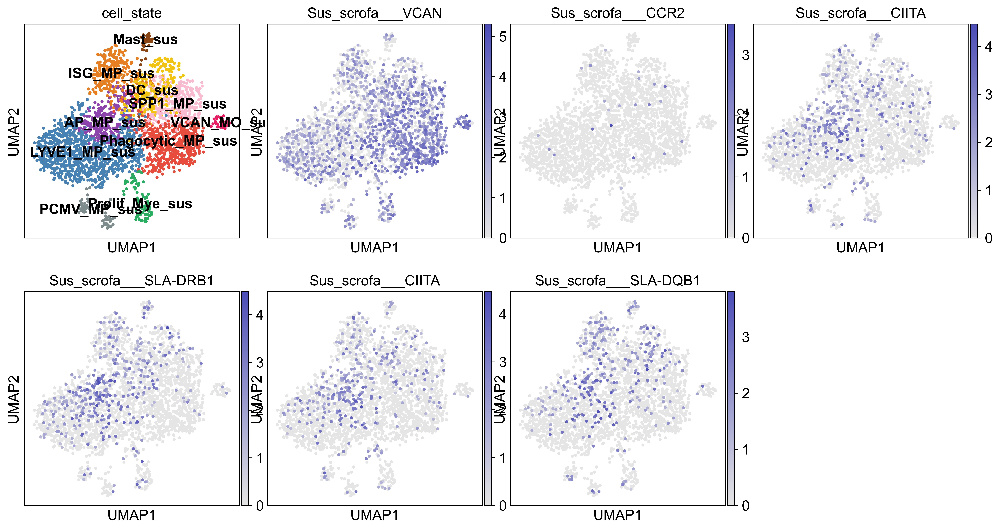

In [5]:

sc.pl.umap( annotated_mye_sus, color=[ 
    # "Condition", 

"cell_state" , 'Sus_scrofa___VCAN', 'Sus_scrofa___CCR2', 'Sus_scrofa___CIITA',
    'Sus_scrofa___SLA-DRB1', 'Sus_scrofa___CIITA', 'Sus_scrofa___SLA-DQB1'

],
            legend_loc="on data",  size=35, wspace = 0.03, cmap = dimplot_color
)


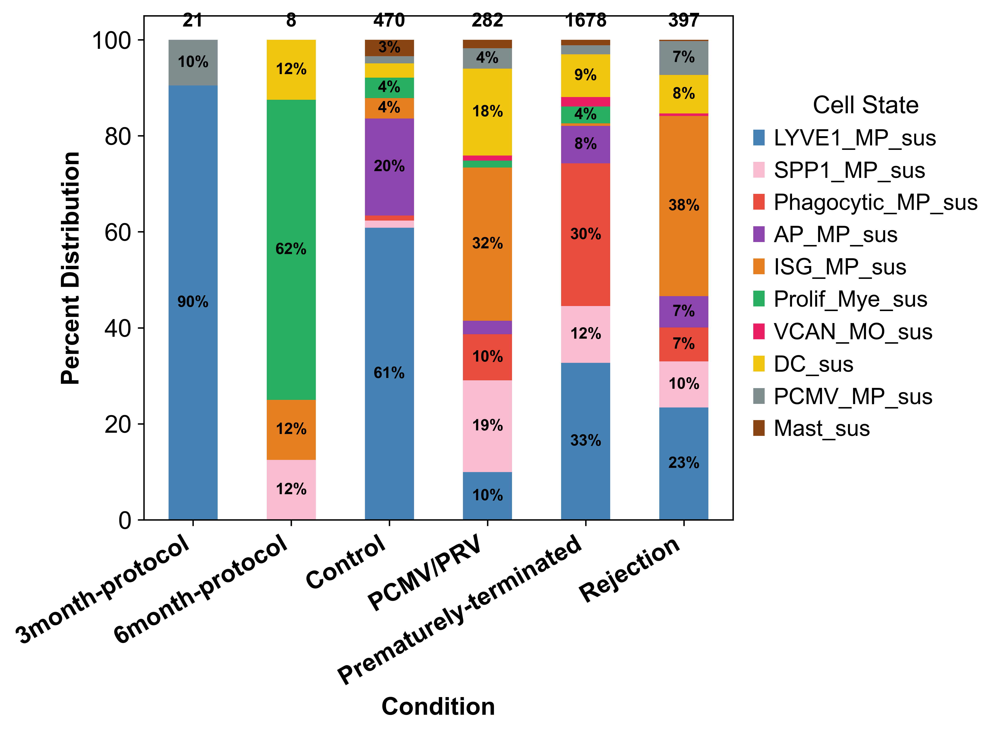

In [7]:
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

def stacked_barplot(adata, xaxis, stack, xaxis_label, legend_label, xaxis_rotation=30, figsize=(8, 6), percent=True):
    
    # 1. Prepare data
    crosstab = pd.crosstab(adata.obs[xaxis], adata.obs[stack])
    # Ensure the order of bars matches the state_order defined in your categorical data
    crosstab = crosstab[adata.obs[stack].cat.categories]
    tmp = crosstab.sum(axis=1)
    ax_data = crosstab.apply(lambda r: r/r.sum()*100, axis=1)
    
    # 2. Get colors from object
    colors = adata.uns.get(f"{stack}_colors", sc.pl.palettes.default_102[:len(ax_data.columns)])
    
    # 3. Plot
    fig, ax = plt.subplots(figsize=figsize)
    ax_plot = ax_data.plot.bar(stacked=True, rot=0, color=colors, ax=ax)
    
    # 4. Labels and Legend
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title=legend_label, frameon=False)
    plt.xlabel(xaxis_label, fontweight="bold")
    plt.ylabel('Percent Distribution', fontweight="bold")
    
    # 5. Percentage labels inside bars
    if percent:
        for rec in ax_plot.patches:
            height = rec.get_height()
            if height > 3: # Only label if bar is significant
                ax_plot.text(rec.get_x() + rec.get_width() / 2, 
                             rec.get_y() + height / 2, 
                             f"{height:.0f}%",
                             ha='center', va='center', fontsize=9, weight='bold')
    
    # 6. FIX: Pin labels to the center of each bar
    # Get the center positions of the bars
    bar_positions = [patch.get_x() + patch.get_width() / 2 for patch in ax.patches[:len(ax_data.index)]]
    
    ax.set_xticks(bar_positions)
    ax.set_xticklabels(ax_data.index, rotation=xaxis_rotation, ha='right', fontweight='bold')
    
    # Add total cell counts exactly at the top of each bar group
    for i, pos in enumerate(bar_positions):
        ax.text(pos, 102, str(int(tmp.iloc[i])), ha='center', va='bottom', fontsize=11, weight='bold')
    
    ax.grid(False)
    plt.margins(x=0.05) # Add small buffer so labels don't get cut off
    plt.tight_layout()
    plt.show()

# Run the function
stacked_barplot(
    annotated_mye_sus, 
    xaxis='Condition', 
    stack='cell_state', 
    xaxis_label='Condition', 
    legend_label='Cell State', 
    xaxis_rotation=30, 
    figsize=(8, 6), 
    percent=True
)

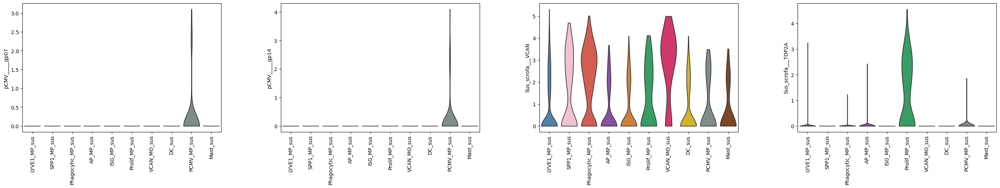

In [9]:
cluster_key = 'cell_state'        # or 'FB_clusters' or whatever you used

qc_vars = ['pCMV_____gp07', 'pCMV_____gp14', 'Sus_scrofa___VCAN',
           "Sus_scrofa___TOP2A", 
           # 'total_counts', 'percent_mito', 'doublet_score'
          ]

sc.pl.violin(
    annotated_mye_sus,
    qc_vars,
    groupby=cluster_key,
    rotation=90,
    stripplot=False,
    multi_panel=True
)


In [16]:
annotated_mye_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Annotated_Mye_sus_v3.h5ad')

In [ ]:
    'Sus_scrofa___SPP1',
    'Sus_scrofa___PLA2G7',
    'Sus_scrofa___MATK',
    'Sus_scrofa___FABP5',
    'Sus_scrofa___GPNMB',
    'Sus_scrofa___IFI30',
    'Sus_scrofa___S100A6',
    'Sus_scrofa___ALCAM',
    'Sus_scrofa___APOE',
    'Sus_scrofa___ANPEP',
    'Sus_scrofa___MYO1E',
    'Sus_scrofa___PPARG',
    'Sus_scrofa___FAM20C',
    'Sus_scrofa___RAB7B',
    'Sus_scrofa___MMP19',
    'Sus_scrofa___EMP1',
    'Sus_scrofa___SCIN',
    'Sus_scrofa___MITF',
    'Sus_scrofa___ITGAX',
    'Sus_scrofa___DHRS9',
    'Sus_scrofa___LGMN',
]

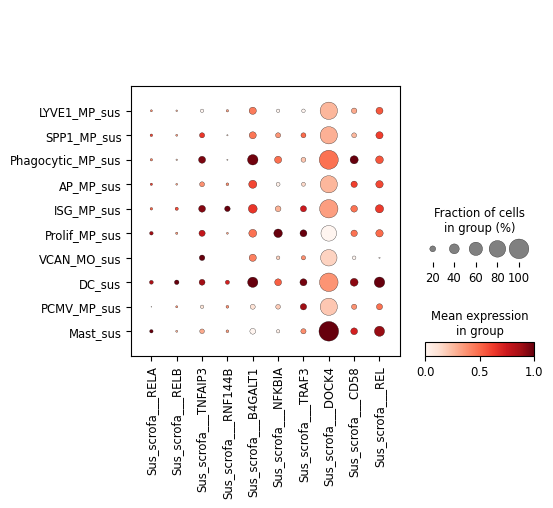

In [32]:
sc.pl.dotplot(
    annotated_mye_sus, 
    var_names=[
    'Sus_scrofa___RELA',
    'Sus_scrofa___RELB',
    'Sus_scrofa___TNFAIP3',
    'Sus_scrofa___RNF144B',
    'Sus_scrofa___B4GALT1',
    'Sus_scrofa___NFKBIA',
    'Sus_scrofa___TRAF3', 

    'Sus_scrofa___DOCK4',
    'Sus_scrofa___CD58',
    'Sus_scrofa___REL',
    # 'Sus_scrofa___PPARG',
    # 'Sus_scrofa___FAM20C',
    # 'Sus_scrofa___RAB7B',
    # 'Sus_scrofa___MMP19',
    # 'Sus_scrofa___EMP1',
    # 'Sus_scrofa___SCIN',
    # 'Sus_scrofa___MITF',
    # 'Sus_scrofa___DHRS9',
    # 'Sus_scrofa___LGMN',
    #         'Sus_scrofa___FABP4',

        
    ], 
    groupby='cell_state', 
    # standard_scale='var',  # Scales expression from 0 to 1 for better comparison
    cmap='Reds', 
    standard_scale = 'var',
    # use_raw = True

)
    

# DEA annotated

In [8]:
annotated_mye_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Annotated_Mye_sus_v3.h5ad')

In [9]:

# Perform differential expressxion to find marker genes for each cluster using Wilcoxon test on raw data
sc.tl.rank_genes_groups(annotated_mye_sus, 'cell_state', method='wilcoxon', key_added='wilcoxon', use_raw=True)

# Visualize the top marker genes for each cluster
sc.pl.rank_genes_groups(annotated_mye_sus, key='wilcoxon', n_genes=30, sharey=False)

# Save the DE analysis to an H5AD file
annotated_mye_sus.write ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/dea_annotated_Mye_sus_v3.h5ad')


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [14]:
dea_annotated_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/dea_annotated_Mye_sus_v3.h5ad')


In [11]:
%matplotlib inline

sc.pl.rank_genes_groups_dotplot(dea_annotated_adata, key="wilcoxon", n_genes=5, standard_scale="var"
                                # , cmap="coolwarm", vmin= -1
                               )


In [15]:
import pandas as pd
import os

de_key = 'wilcoxon'  # The key you used in rank_genes_groups
results = dea_annotated_adata.uns[de_key]
clusters = results['names'].dtype.names  # These are your clusters

output_dir = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/Annotated_DEGs"
os.makedirs(output_dir, exist_ok=True)

for clust in clusters:
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    # Optional: Sort by Wilcoxon score, descending (highest first)
    df = df.sort_values('score', ascending=False)
    # Save to CSV
    df.to_csv(f"{output_dir}/Cluster_{clust}_DEGs.csv", index=False)



In [16]:
import os
import pandas as pd

# 1. Setup paths
base_results_dir = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/Annotated_DEGs"
sig_output_dir = os.path.join(base_results_dir, "significant_DEGs")
os.makedirs(sig_output_dir, exist_ok=True)

# 2. Thresholds
P_ADJ_CUTOFF = 0.05
LFC_CUTOFF = 0.5

print(f"Filtering DEGs: pval_adj < {P_ADJ_CUTOFF} and |logfoldchange| > {LFC_CUTOFF}")

# 3. Process each cluster's results from your previous loop
# Using the 'clusters' variable from your previous code block
for clust in clusters:
    # Extract data from the scanpy results object
    gene_names = results['names'][clust]
    scores = results['scores'][clust]
    logfoldchanges = results['logfoldchanges'][clust]
    pvals = results['pvals'][clust]
    pvals_adj = results['pvals_adj'][clust]
    
    # Create the DataFrame
    df = pd.DataFrame({
        'gene': gene_names,
        'score': scores,
        'logfoldchange': logfoldchanges,
        'pval': pvals,
        'pval_adj': pvals_adj,
    })
    
    # 4. Apply strict filtering
    # Filtering for p-adj AND (|LFC| > 0.75)
    sig_df = df[
        (df['pval_adj'] < P_ADJ_CUTOFF) & 
        ((df['logfoldchange'] > LFC_CUTOFF) | (df['logfoldchange'] < -LFC_CUTOFF))
    ].copy()
    
    # Sort by logfoldchange descending
    sig_df = sig_df.sort_values('logfoldchange', ascending=False)
    
    # 5. Save if there are significant genes found
    if not sig_df.empty:
        output_file = f"{sig_output_dir}/Significant_Cluster_{clust}_DEGs.csv"
        sig_df.to_csv(output_file, index=False)
        print(f"  Cluster {clust}: Saved {len(sig_df)} significant DEGs.")
    else:
        print(f"  Cluster {clust}: No genes met the significance criteria.")

print("\nAll significant files saved in:", sig_output_dir)

Filtering DEGs: pval_adj < 0.05 and |logfoldchange| > 0.5
  Cluster LYVE1_MP_sus: Saved 677 significant DEGs.
  Cluster SPP1_MP_sus: Saved 227 significant DEGs.
  Cluster Phagocytic_MP_sus: Saved 672 significant DEGs.
  Cluster AP_MP_sus: Saved 81 significant DEGs.
  Cluster ISG_MP_sus: Saved 496 significant DEGs.
  Cluster Prolif_Mye_sus: Saved 61 significant DEGs.
  Cluster VCAN_MO_sus: Saved 4 significant DEGs.
  Cluster DC_sus: Saved 143 significant DEGs.
  Cluster PCMV_MP_sus: No genes met the significance criteria.
  Cluster Mast_sus: Saved 163 significant DEGs.

All significant files saved in: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/Annotated_DEGs/significant_DEGs


In [17]:
dea_annotated_adata

AnnData object with n_obs × n_vars = 2856 × 4003
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'cell_type', 'leiden_03', 'leiden_04', 'leiden_05', 'leiden_06', 'leiden_07', 'leiden_08', 'leiden_09', 'leiden_10', 'leiden_11', 'leiden_12', 'leiden_13', 'leiden_14', 'cell_state'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'Condition_colors', 'Sample_ID_colors', 'cell

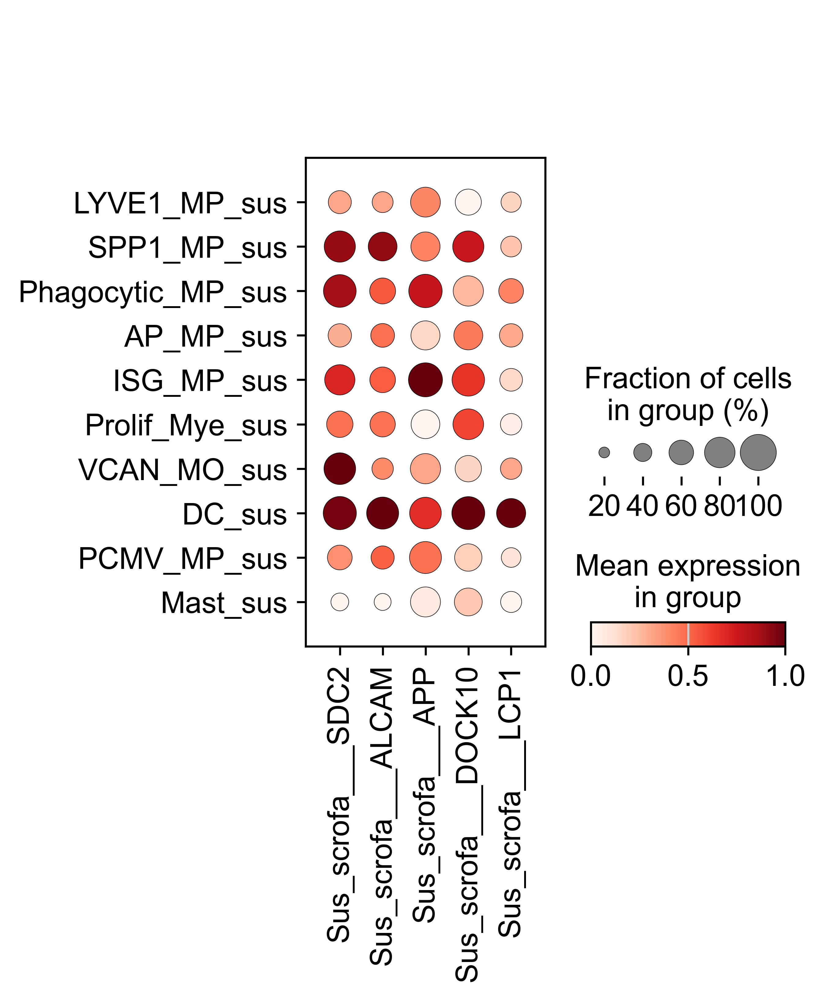

In [18]:
sc.pl.dotplot(
    dea_annotated_adata, 
    var_names=[
'Sus_scrofa___SDC2',
'Sus_scrofa___ALCAM',
'Sus_scrofa___APP',
'Sus_scrofa___DOCK10','Sus_scrofa___LCP1',
        
    ], 
    groupby='cell_state', 
    # standard_scale='var',  # Scales expression from 0 to 1 for better comparison
    cmap='Reds', 
    standard_scale = 'var',
    # use_raw = True

)
    

# New label transfer with X_UMAP

In [2]:
import os
import scanpy as sc
import pandas as pd

# ---------------------------
# PATHS
# ---------------------------
OBJECTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects"

annotated_adata = sc.read ("/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Annotated_Mye_sus_v3.h5ad")

raw_adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v2/objects/very_cleaned_raw_Mye_sus_v2.h5ad')

SAVE_PATH = os.path.join(OBJECTS_DIR, "Annotated_Raw_Mye_sus_preclinical_xeno_v1.h5ad")

print(f"Annotated cells: {annotated_adata.n_obs}")
print(f"Raw cells: {raw_adata.n_obs}")

# ---------------------------
# LABEL TRANSFER
# ---------------------------
# Create a mapping series from the annotated object
label_map = annotated_adata.obs['cell_state']

# Map these to the raw object (this ensures cells align by index)
raw_adata.obs['cell_state'] = raw_adata.obs_names.map(label_map)

# ---------------------------
# UNS TRANSFER
# ---------------------------
# Transfer the color dictionary
if 'cell_state_colors' in annotated_adata.uns:
    raw_adata.uns['cell_state_colors'] = annotated_adata.uns['cell_state_colors']
    print("Transferred cell_state_colors to raw object.")

# ---------------------------
# VALIDATION & FILTERING
# ---------------------------
n_missing = raw_adata.obs['cell_state'].isna().sum()
if n_missing > 0:
    print(f"WARNING: {n_missing} cells in the raw object could not be mapped. Removing them...")
    # Filter out any cells that have NaN in the cell_state column
    raw_adata = raw_adata[raw_adata.obs['cell_state'].notna()].copy()
    print(f"Cells remaining after filter: {raw_adata.n_obs}")
else:
    print("All cells successfully mapped.")

# ---------------------------
# UMAP TRANSFER
# ---------------------------
# We align the UMAP matrix by cell barcodes to ensure perfect mathematical alignment
if 'X_umap' in annotated_adata.obsm:
    # Convert annotated UMAP to a DataFrame indexed by cell barcodes
    umap_df = pd.DataFrame(
        annotated_adata.obsm['X_umap'], 
        index=annotated_adata.obs_names
    )
    
    # Slice the dataframe to match the exact order and composition of the filtered raw object
    aligned_umap = umap_df.loc[raw_adata.obs_names].values
    
    # Assign it safely to the raw object's .obsm
    raw_adata.obsm['X_umap'] = aligned_umap
    print("Transferred UMAP coordinates to raw object.")
else:
    print("WARNING: 'X_umap' not found in annotated_adata.obsm. Skipping UMAP transfer.")

# ---------------------------
# SAVE
# ---------------------------
raw_adata.write(SAVE_PATH)
print(f"\nSaved annotated raw object to: {SAVE_PATH}")

Annotated cells: 2856
Raw cells: 2856
Transferred cell_state_colors to raw object.
All cells successfully mapped.
Transferred UMAP coordinates to raw object.

Saved annotated raw object to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Annotated_Raw_Mye_sus_preclinical_xeno_v1.h5ad


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [8]:
raw_annotated_mye_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Annotated_Raw_Mye_sus_preclinical_xeno_v1.h5ad')

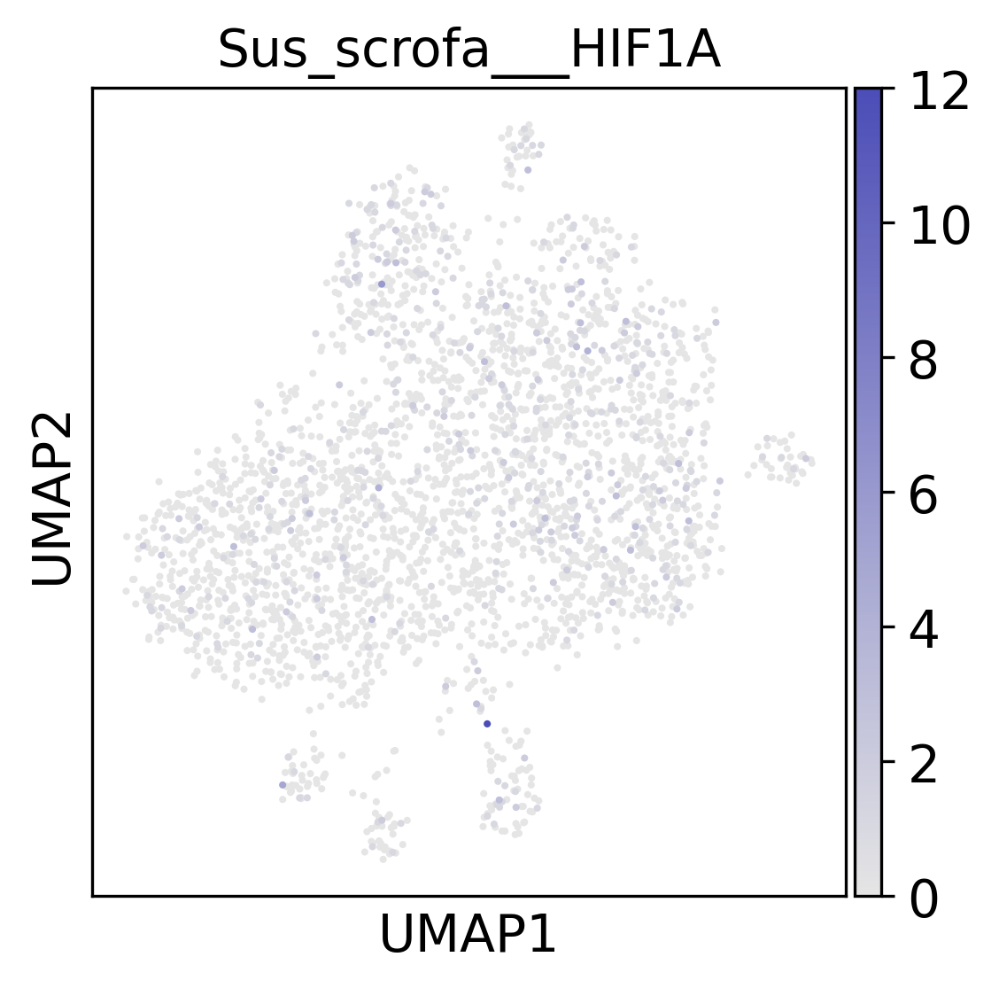

In [5]:
# --- 3. CREATE CUSTOM COLORMAP ---

sc.pl.umap(
    raw_annotated_mye_sus, 
    color="Sus_scrofa___HIF1A", 
 cmap=dimplot_color,
    size=15,
    legend_loc="right margin"
)

# Final UMAP of Mye_sus

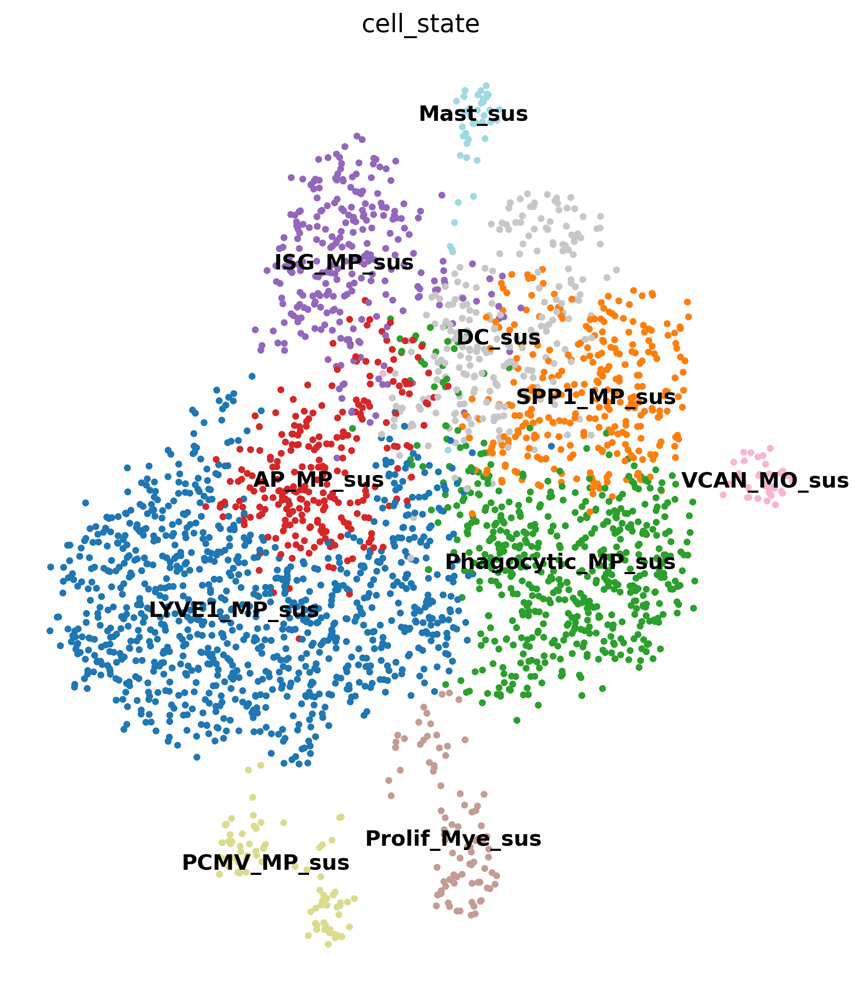

In [3]:
adata = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Annotated_Raw_Mye_sus_preclinical_xeno_v1.h5ad')

fig, ax = plt.subplots(figsize=(7, 8))

sc.pl.umap(
    adata,
    color="cell_state",
    palette="tab20",
    frameon=False,
    legend_loc="on data",
    #legend_fontoutline=0.5,
    size=60,
    legend_fontsize=12,
    ax=ax,
    show=False,
)

# Rasterize the UMAP point cloud to keep the PDF file size manageable
# while axes and on-data labels remain vector-based
ax.set_rasterization_zorder(2)

ax.set_xlabel("UMAP1", fontsize=16, loc="left")
ax.set_ylabel("UMAP2", fontsize=16, loc="bottom")
ax.tick_params(labelbottom=True, labelleft=True, labelsize=14)

plt.tight_layout()

fig.savefig(
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/"
    "UMAP_Mye_sus_final.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# Old label transfer

In [19]:
import os
import scanpy as sc
import pandas as pd

# ---------------------------
# PATHS
# ---------------------------
OBJECTS_DIR = "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects"
ANNOTATED_PATH = os.path.join(OBJECTS_DIR, "Annotated_Mye_sus_v3.h5ad")
RAW_PATH = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v2/objects/very_cleaned_raw_Mye_sus_v2.h5ad'
SAVE_PATH = os.path.join(OBJECTS_DIR, "Raw_annotated_Myeloids_sus_v3.h5ad")

# ---------------------------
# LOAD DATA
# ---------------------------
annotated_mye_sus = sc.read(ANNOTATED_PATH)
raw_myeloids = sc.read(RAW_PATH)

print(f"Annotated cells: {annotated_mye_sus.n_obs}")
print(f"Raw cells: {raw_myeloids.n_obs}")

# ---------------------------
# LABEL TRANSFER
# ---------------------------
# Create a mapping series from the annotated object
label_map = annotated_mye_sus.obs['cell_state']

# Map these to the raw object (this ensures cells align by index)
# Cells in raw_myeloids not present in annotated_mye_sus will become NaN
raw_myeloids.obs['cell_state'] = raw_myeloids.obs_names.map(label_map)

# ---------------------------
# UNS TRANSFER
# ---------------------------
# Transfer the color dictionary
if 'cell_state_colors' in annotated_mye_sus.uns:
    raw_myeloids.uns['cell_state_colors'] = annotated_mye_sus.uns['cell_state_colors']
    print("Transferred cell_state_colors to raw object.")

# ---------------------------
# VALIDATION
# ---------------------------
n_missing = raw_myeloids.obs['cell_state'].isna().sum()
if n_missing > 0:
    print(f"WARNING: {n_missing} cells in the raw object could not be mapped!")
else:
    print("All cells successfully mapped.")

# ---------------------------
# SAVE
# ---------------------------
raw_myeloids.write(SAVE_PATH)
print(f"\nSaved annotated raw object to: {SAVE_PATH}")

Annotated cells: 2856
Raw cells: 2856
Transferred cell_state_colors to raw object.
All cells successfully mapped.

Saved annotated raw object to: /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Raw_annotated_Myeloids_sus_v3.h5ad


/data/ag_reichart_lindberg/nhadizad/miniconda3/envs/amylo/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


In [7]:
raw_annotated_mye_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Raw_annotated_Myeloids_sus_v3.h5ad')

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Raw_annotated_Myeloids_sus_v3.h5ad', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [21]:
raw_annotated_mye_sus

AnnData object with n_obs × n_vars = 2856 × 53826
    obs: 'Sample_ID', 'source', 'doublet_score', 'predicted_doublet_scrublet', 'n_counts_Sus_scrofa', 'n_counts_Papio_anubis', 'species_origin', 'barnyard_doublet', 'Survival', 'Condition', 'Donor_heart_mass (g)', 'Recipient_heart_mass (g)', 'Recipient_LVEF (%)', 'Recipient_LV_Wall_Thickness (mm)', 'TropT (ng/ml)', 'Immunosuppression_Protocol', 'Heart_Mass_Ratio', 'Exp', 'percent_mito', 'percent_ribo', 'n_genes_by_counts', 'total_counts', 'n_counts', 'n_genes', 'n_counts_PCMV', 'n_genes_PCMV', 'PCMV_score', 'cell_type', 'cell_state'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'Condition_colors', 'Sample_ID_colors', 'cell_state_colors', 'cell_type_colors'
    obsm: 'X_pca_harmony', 'X_umap'

# Composition

In [ ]:
raw_annotated_mye_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Annotated_Raw_Mye_sus_preclinical_xeno_v1.h5ad')

In [11]:
# =============================================================================
# COMPOSITIONAL ANALYSIS — snRNA-seq | Xenotransplant Cohort (Cell Types)
# BARPLOT VERSION (Means + SEM + Jittered Sample Points)
#
# FDR STRATEGY: Per comparison family
# LAYOUT: One subplot per cell_type, independent y-axis scaling
# COMPARISONS: User-defined subset from all available conditions
# =============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import scanpy as sc
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# --- Plotting & Typography Settings ---
sc.settings.set_figure_params(dpi=300, dpi_save=300)
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial"]

# =============================================================================
# 1. CONFIGURATION (CONTROL PANEL)
# =============================================================================

CELLTYPE_COL = "cell_state"

# Define ALL conditions present in your dataset
ALL_CONDITIONS = [
    "Control",
    "3month-protocol",
    "6month-protocol",
    "Prematurely-terminated",
    "PCMV/PRV",
    "Rejection",
]

# Define which conditions to actually RENDER on the barplots
PLOT_CONDS = [
    #"Control",
    "3month-protocol",
    "6month-protocol",
    "Prematurely-terminated",
    "PCMV/PRV",
    "Rejection",
]

# Define the specific pairwise comparisons for statistical testing
ALL_PAIRS = [
    #("3month-protocol", "Control"),
    ("3month-protocol", "6month-protocol"),
    ("3month-protocol", "Prematurely-terminated"),
    ("3month-protocol", "PCMV/PRV"),
    ("3month-protocol", "Rejection"),
]

# --- Visual Layout Parameters ---
NCOND = len(PLOT_CONDS)
FIGSIZE_BY_NCOND = {
    2: (3.0, 4.0),
    3: (3.8, 4.0),
    4: (4.6, 4.0),
    5: (5.0, 5.0),
    6: (6.0, 6.0),
}

BOX_WIDTH = 0.5
BOX_SPACING = 0.6
INNER_XPAD = 0.3

POINT_JITTER = 0.06
POINT_SIZE = 20
POINT_ALPHA = 0.70

# =============================================================================
# 2. PATHS & DATA SETUP
# =============================================================================
RESULTS_DIR = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/composition"
)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Note: Ensure ⁠ raw_annotated_adata ⁠ is loaded in your notebook before running this block
annotated_adata = raw_annotated_mye_sus

# =============================================================================
# 3. ORDERS & COLORS
# =============================================================================
COND_ORDER = ALL_CONDITIONS.copy()

COND_COLORS = {
    "Control": "#EFE48E",
    "3month-protocol": "skyblue",
    "6month-protocol": "#08528f",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}

if annotated_adata.obs[CELLTYPE_COL].dtype.name == "category":
    CELL_TYPE_ORDER = list(annotated_adata.obs[CELLTYPE_COL].cat.categories)
else:
    CELL_TYPE_ORDER = sorted(annotated_adata.obs[CELLTYPE_COL].unique().tolist())

# Keep only selected conditions, in master-condition order
PANEL_CONDS = [c for c in COND_ORDER if c in PLOT_CONDS]

# Keep only explicitly selected pairs where both conditions are plotted
TEST_PAIRS = [
    (c1, c2) for (c1, c2) in ALL_PAIRS
    if (c1 in PANEL_CONDS and c2 in PANEL_CONDS)
]

if NCOND not in FIGSIZE_BY_NCOND:
    raise ValueError(f"NCOND={NCOND} is not defined in FIGSIZE_BY_NCOND.")

SUBPLOT_W, SUBPLOT_H = FIGSIZE_BY_NCOND[NCOND]
X_POS = np.arange(NCOND) * BOX_SPACING

# =============================================================================
# 4. COMPUTE PER-SAMPLE PROPORTIONS
# =============================================================================
df_obs = annotated_adata.obs.copy().reset_index()
df_obs["Condition"] = df_obs["Condition"].astype(str)
df_obs[CELLTYPE_COL] = df_obs[CELLTYPE_COL].astype(str)

df_obs = df_obs[df_obs["Condition"].isin(PANEL_CONDS)].copy()

counts = (
    df_obs.groupby(["Sample_ID", CELLTYPE_COL, "Condition"], observed=False)
    .size()
    .reset_index(name="count")
)
totals = (
    df_obs.groupby(["Sample_ID", "Condition"], observed=False)
    .size()
    .reset_index(name="total")
)

prop_df = counts.merge(totals, on=["Sample_ID", "Condition"], how="left")
prop_df["proportion"] = (prop_df["count"] / prop_df["total"]) * 100

prop_df["Condition"] = pd.Categorical(prop_df["Condition"], categories=PANEL_CONDS, ordered=True)
prop_df[CELLTYPE_COL] = pd.Categorical(prop_df[CELLTYPE_COL], categories=CELL_TYPE_ORDER, ordered=True)

# =============================================================================
# 5. STATISTICS
# =============================================================================
raw_rows = []

for (c1, c2) in TEST_PAIRS:
    pair_rows = []

    for ct in CELL_TYPE_ORDER:
        ct_data = prop_df[prop_df[CELLTYPE_COL] == ct]

        v1 = ct_data[ct_data["Condition"] == c1]["proportion"].dropna().values
        v2 = ct_data[ct_data["Condition"] == c2]["proportion"].dropna().values

        mean1   = np.mean(v1)   if len(v1) > 0 else np.nan
        mean2   = np.mean(v2)   if len(v2) > 0 else np.nan
        median1 = np.median(v1) if len(v1) > 0 else np.nan
        median2 = np.median(v2) if len(v2) > 0 else np.nan

        if mean1 > 0 and mean2 > 0:
            lfc, fc = np.log2(mean2 / mean1), mean2 / mean1
        elif mean1 == 0 and mean2 > 0:
            lfc, fc = np.inf, np.inf
        elif mean1 > 0 and mean2 == 0:
            lfc, fc = -np.inf, 0.0
        else:
            lfc, fc = np.nan, np.nan

        if len(v1) >= 2 and len(v2) >= 2:
            _, pval = mannwhitneyu(v1, v2, alternative="two-sided")
        else:
            pval = np.nan

        pair_rows.append({
            CELLTYPE_COL: ct, "group1": c1, "group2": c2,
            "comparison": f"{c2}vs{c1}", "fdr_family": f"{c2}vs{c1}",
            "mean_group1": mean1, "mean_group2": mean2,
            "median_group1": median1, "median_group2": median2,
            "fold_change": fc, "log2FC": lfc, "p_val": pval,
        })

    pvals_arr = np.array([r["p_val"] for r in pair_rows], dtype=float)
    valid_mask = ~np.isnan(pvals_arr)
    fdr_arr = np.full(len(pvals_arr), np.nan)

    if valid_mask.sum() > 0:
        _, fdr_valid, _, _ = multipletests(pvals_arr[valid_mask], method="fdr_bh")
        fdr_arr[valid_mask] = fdr_valid

    for i, row in enumerate(pair_rows):
        row["fdr_adj_p_val"] = fdr_arr[i]

    raw_rows.extend(pair_rows)

stats_df = pd.DataFrame(raw_rows)

def get_stars(p):
    if pd.isna(p): return ""
    if p < 0.001: return "*"
    if p < 0.01: return "**"
    if p < 0.05: return "*"
    return ""

stats_df["significance"] = stats_df["fdr_adj_p_val"].apply(get_stars) if len(stats_df) > 0 else pd.Series(dtype=object)

out_csv = os.path.join(RESULTS_DIR, "Compositional_Stats_Mye_sus_SelectedComparisons_PerPairFDR.csv")
stats_df.sort_values(["comparison", "fdr_adj_p_val"]).to_csv(out_csv, index=False, float_format="%.6g")
print(f"Stats CSV saved -> {out_csv}")

# =============================================================================
# 6. PLOT — BARPLOTS
# =============================================================================
sns.set_style("white")

N_STATE = len(CELL_TYPE_ORDER)
N_COLS = min(4, N_STATE)
N_ROWS = int(np.ceil(N_STATE / N_COLS))

fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(SUBPLOT_W * N_COLS, SUBPLOT_H * N_ROWS), squeeze=False)
axes_flat = axes.flatten()

Y_START_ABOVE_DATA = 0.06
Y_STEP             = 0.09
BRACKET_H_FRAC     = 0.02
STAR_OFFSET_FRAC   = 0.01

rng = np.random.default_rng(12345)

for idx, ct in enumerate(CELL_TYPE_ORDER):
    ax = axes_flat[idx]
    ct_data = prop_df[prop_df[CELLTYPE_COL] == ct]

    # Calculate means and SEMs
    means, sems, colors_list = [], [], []
    for cond in PANEL_CONDS:
        vals = ct_data.loc[ct_data["Condition"] == cond, "proportion"].dropna().values
        colors_list.append(COND_COLORS[cond])
        if len(vals) > 0:
            means.append(np.mean(vals))
            sems.append(np.std(vals, ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0)
        else:
            means.append(0)
            sems.append(0)

    # Draw Barplots with SEM Error Bars
    ax.bar(
        X_POS, means, width=BOX_WIDTH, yerr=sems, 
        color=colors_list, alpha=0.85, edgecolor="black", linewidth=1.0,
        error_kw=dict(ecolor='black', lw=1.2, capsize=3, capthick=1.2)
    )

    # Overlay Individual Jittered Scatter Points
    for x, cond in zip(X_POS, PANEL_CONDS):
        vals = ct_data.loc[ct_data["Condition"] == cond, "proportion"].dropna().values
        if len(vals) == 0: continue
        jitter = rng.uniform(-POINT_JITTER, POINT_JITTER, size=len(vals))
        ax.scatter(
            np.full(len(vals), x) + jitter, vals,
            s=POINT_SIZE, alpha=POINT_ALPHA,
            facecolors="white", edgecolors="black", linewidths=0.7, zorder=3,
        )

    # Panel styling
    ax.set_xlim(X_POS[0] - INNER_XPAD, X_POS[-1] + INNER_XPAD)
    ax.grid(False)
    ax.set_title(ct, fontsize=12, fontweight="bold", pad=8)
    ax.set_xlabel("")
    ax.set_ylabel("Proportion (%)", fontsize=10, fontweight="bold")
    ax.set_xticks(X_POS)
    ax.set_xticklabels(PANEL_CONDS, rotation=45, ha="right")
    
    ax.tick_params(axis="both", which="both", labelsize=8, width=0.8, length=3, direction="out")
    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(0.8)
        ax.spines[spine].set_color("black")

    # Significance Annotation
    sig_pairs = stats_df[(stats_df[CELLTYPE_COL] == ct) & (stats_df["significance"] != "")].sort_values("fdr_adj_p_val")
    
    max_val = ct_data["proportion"].max()
    if pd.isna(max_val): max_val = 1.0

    if sig_pairs.empty:
        ax.set_ylim(0, max_val * 1.15)
        continue

    data_range = max_val if max_val > 0 else 1.0
    base_y = max_val + Y_START_ABOVE_DATA * data_range
    n_layers = len(sig_pairs)
    top_y = base_y + (n_layers - 1) * Y_STEP * data_range + BRACKET_H_FRAC * data_range + STAR_OFFSET_FRAC * data_range
    ax.set_ylim(0, top_y * 1.08)

    for layer, (_, row) in enumerate(sig_pairs.iterrows()):
        y_bar = base_y + layer * Y_STEP * data_range
        bracket_h = BRACKET_H_FRAC * data_range
        star_offset = STAR_OFFSET_FRAC * data_range

        x1 = X_POS[PANEL_CONDS.index(row["group1"])]
        x2 = X_POS[PANEL_CONDS.index(row["group2"])]
        if x1 > x2: x1, x2 = x2, x1

        ax.plot([x1, x1, x2, x2], [y_bar, y_bar + bracket_h, y_bar + bracket_h, y_bar], color="black", lw=1.0, clip_on=False)
        ax.text(
            (x1 + x2) / 2, y_bar + bracket_h + star_offset, row["significance"],
            ha="center", va="bottom", fontsize=8, fontweight="bold", color="black", clip_on=False
        )

for j in range(N_STATE, len(axes_flat)):
    axes_flat[j].axis("off")

fig.suptitle("Cell state Composition — Mye_sus (Xenotransplant Cohort)", fontsize=16, fontweight="bold", y=1.0)

handles = [mpatches.Patch(facecolor=COND_COLORS[c], edgecolor="black", linewidth=0.8, label=c, alpha=0.85) for c in PANEL_CONDS]
fig.legend(handles=handles, title="Condition", title_fontsize=11, fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=min(6, len(PANEL_CONDS)), frameon=True, framealpha=0.85, edgecolor="black")

plt.tight_layout(rect=[0, 0.03, 1, 0.97])

# =============================================================================
# 7. EXPORT
# =============================================================================
out_pdf = os.path.join(RESULTS_DIR, "Compositional_CellState_Mye_sus_preclinical_SelectedComparisons_PerPanel.pdf")
out_png = os.path.join(RESULTS_DIR, "Compositional_CellState_Mye_sus_preclinical_SelectedComparisons_PerPanel.png")

plt.savefig(out_pdf, dpi=300, bbox_inches="tight")
plt.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()

print(f"\nPlot  -> {out_pdf}")
print(f"      -> {out_png}")

sig_summary = stats_df[stats_df["significance"] != ""][[CELLTYPE_COL, "comparison", "mean_group1", "mean_group2", "log2FC", "p_val", "fdr_adj_p_val", "significance"]].sort_values([CELLTYPE_COL, "fdr_adj_p_val"])
print(f"\n=== Significant pairs — per-pair BH-FDR (FDR < 0.05), selected comparisons | n = {len(sig_summary)} ===")
print(sig_summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


Stats CSV saved -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/composition/Compositional_Stats_Mye_sus_SelectedComparisons_PerPairFDR.csv



Plot  -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/composition/Compositional_CellState_Mye_sus_preclinical_SelectedComparisons_PerPanel.pdf
      -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/composition/Compositional_CellState_Mye_sus_preclinical_SelectedComparisons_PerPanel.png

=== Significant pairs — per-pair BH-FDR (FDR < 0.05), selected comparisons | n = 8 ===
       cell_state                              comparison  mean_group1  mean_group2  log2FC  p_val  fdr_adj_p_val significance
        AP_MP_sus Prematurely-terminatedvs3month-protocol       0.0000       7.8132     inf 0.0168         0.0210            *
           DC_sus Prematurely-terminatedvs3month-protocol       0.0000       9.0644     inf 0.0168         0.0210            *
       ISG_MP_sus Prematurely-terminatedvs3month-protocol       0.0000       0.5262     inf 0.0168         0.021

# Pearson & scatter plots

In [22]:
raw_annotated_mye_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Raw_annotated_Myeloids_sus_v3.h5ad')

In [27]:
# Compositional analysis- boxplots
sc.settings.set_figure_params(dpi=300, dpi_save=300)
# 42 is for TrueType fonts (editable text in Illustrator)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42


"""
=============================================================================
COMPOSITIONAL ANALYSIS — snRNA-seq | Xenotransplant Cohort (Cell Types)
FDR STRATEGY: Per comparison family
LAYOUT: One subplot per cell_type, independent y-axis scaling
COMPARISONS: User-defined subset from all available conditions
=============================================================================
Statistical design:
  - Mann-Whitney U test (two-sided) for each cell type x pair combination
  - BH FDR correction applied WITHIN each pairwise comparison family
    across all cell types.
  - Only selected conditions are tested
  - Only selected conditions are shown on the plot
  - Only pairs with FDR < 0.05 are annotated on the plot
=============================================================================
"""

import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import scanpy as sc
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# --- Adobe Illustrator-compatible fonts ---
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Arial"]

# =============================================================================
# USER SETTINGS
# =============================================================================

#
# EXPLANATION: 1. Choose CELLTYPE_COL, 2. CHOOSE PLOT_CONDS 3. CHOOSE ALL_PAIRS 4. OPTIONAL: If wanted size of subplots can be manually adjusted if needed
#

# CELLTYPE_COL = "cell_state"
CELLTYPE_COL = "cell_state"

ALL_CONDITIONS = [
    "Control",
    "3month-protocol",
    "6month-protocol",
    "Prematurely-terminated",
    "PCMV/PRV",
    "Rejection",
]

PLOT_CONDS = [
    "Control",
    "3month-protocol",
    "6month-protocol",
    "Prematurely-terminated",
    "PCMV/PRV",
    "Rejection",
]

ALL_PAIRS = [
    ("3month-protocol", "Control"),
    ("3month-protocol", "6month-protocol"),
    ("3month-protocol", "Prematurely-terminated"),
    ("3month-protocol", "PCMV/PRV"),
    ("3month-protocol", "Rejection"),
]

# Number of shown conditions
NCOND = len(PLOT_CONDS)

# Standardized subplot sizes by number of shown conditions
FIGSIZE_BY_NCOND = {
    #   width, height
    2: (3.0, 4.0),
    3: (3.8, 4.0),
    4: (4.6, 4.0),
    5: (5.0, 5.0),
    6: (6.0, 6.0),
}

# Fixed box width and spacing across all plots
BOX_WIDTH = 0.5
BOX_SPACING = 0.6
INNER_XPAD = 0.3

# Scatter styling
POINT_JITTER = 0.06
POINT_SIZE = 20
POINT_ALPHA = 0.60

# =============================================================================
# 0. PATHS & DATA
# =============================================================================
RESULTS_DIR = (
    "/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/composition"
)
os.makedirs(RESULTS_DIR, exist_ok=True)

annotated_adata = raw_annotated_mye_sus

# =============================================================================
# 1. ORDERS, COLORS & EXPLICIT PAIRS
# =============================================================================
COND_ORDER = ALL_CONDITIONS.copy()

COND_COLORS = {
    "Control": "#EFE48E",
    "3month-protocol": "skyblue",
    "6month-protocol": "#08528f",
    "Prematurely-terminated": "#C9B8D9",
    "PCMV/PRV": "#F0C096",
    "Rejection": "#E09E9E",
}

if annotated_adata.obs[CELLTYPE_COL].dtype.name == "category":
    CELL_TYPE_ORDER = list(annotated_adata.obs[CELLTYPE_COL].cat.categories)
else:
    CELL_TYPE_ORDER = sorted(annotated_adata.obs[CELLTYPE_COL].unique().tolist())

# Keep only selected conditions, in master-condition order
PANEL_CONDS = [c for c in COND_ORDER if c in PLOT_CONDS]

# Keep only explicitly selected pairs where both conditions are in PANEL_CONDS
TEST_PAIRS = [
    (c1, c2) for (c1, c2) in ALL_PAIRS
    if (c1 in PANEL_CONDS and c2 in PANEL_CONDS)
]

if NCOND not in FIGSIZE_BY_NCOND:
    raise ValueError(
        f"NCOND={NCOND} is not defined in FIGSIZE_BY_NCOND. "
        f"Please add a figsize entry for this number of conditions."
    )

SUBPLOT_W, SUBPLOT_H = FIGSIZE_BY_NCOND[NCOND]

# Fixed x positions for true spacing control
X_POS = np.arange(NCOND) * BOX_SPACING

# =============================================================================
# 2. COMPUTE PER-SAMPLE PROPORTIONS
# =============================================================================
df_obs = annotated_adata.obs.copy().reset_index()
df_obs["Condition"] = df_obs["Condition"].astype(str)
df_obs[CELLTYPE_COL] = df_obs[CELLTYPE_COL].astype(str)

# Keep only selected conditions
df_obs = df_obs[df_obs["Condition"].isin(PANEL_CONDS)].copy()

counts = (
    df_obs
    .groupby(["Sample_ID", CELLTYPE_COL, "Condition"], observed=False)
    .size()
    .reset_index(name="count")
)
totals = (
    df_obs
    .groupby(["Sample_ID", "Condition"], observed=False)
    .size()
    .reset_index(name="total")
)

prop_df = counts.merge(totals, on=["Sample_ID", "Condition"], how="left")
prop_df["proportion"] = (prop_df["count"] / prop_df["total"]) * 100

prop_df["Condition"] = pd.Categorical(
    prop_df["Condition"], categories=PANEL_CONDS, ordered=True
)
prop_df[CELLTYPE_COL] = pd.Categorical(
    prop_df[CELLTYPE_COL], categories=CELL_TYPE_ORDER, ordered=True
)

# =============================================================================
# 3. STATISTICS
# =============================================================================
raw_rows = []

for (c1, c2) in TEST_PAIRS:
    pair_rows = []

    for ct in CELL_TYPE_ORDER:
        ct_data = prop_df[prop_df[CELLTYPE_COL] == ct]

        v1 = ct_data[ct_data["Condition"] == c1]["proportion"].dropna().values
        v2 = ct_data[ct_data["Condition"] == c2]["proportion"].dropna().values

        mean1   = np.mean(v1)   if len(v1) > 0 else np.nan
        mean2   = np.mean(v2)   if len(v2) > 0 else np.nan
        median1 = np.median(v1) if len(v1) > 0 else np.nan
        median2 = np.median(v2) if len(v2) > 0 else np.nan

        if mean1 > 0 and mean2 > 0:
            lfc = np.log2(mean2 / mean1)
            fc  = mean2 / mean1
        elif mean1 == 0 and mean2 > 0:
            lfc, fc = np.inf, np.inf
        elif mean1 > 0 and mean2 == 0:
            lfc, fc = -np.inf, 0.0
        else:
            lfc, fc = np.nan, np.nan

        if len(v1) >= 2 and len(v2) >= 2:
            _, pval = mannwhitneyu(v1, v2, alternative="two-sided")
        else:
            pval = np.nan

        pair_rows.append({
            CELLTYPE_COL:    ct,
            "group1":        c1,
            "group2":        c2,
            "comparison":    f"{c2}vs{c1}",
            "fdr_family":    f"{c2}vs{c1}",
            "mean_group1":   mean1,
            "mean_group2":   mean2,
            "median_group1": median1,
            "median_group2": median2,
            "fold_change":   fc,
            "log2FC":        lfc,
            "p_val":         pval,
        })

    pvals_arr = np.array([r["p_val"] for r in pair_rows], dtype=float)
    valid_mask = ~np.isnan(pvals_arr)
    fdr_arr = np.full(len(pvals_arr), np.nan)

    if valid_mask.sum() > 0:
        _, fdr_valid, _, _ = multipletests(
            pvals_arr[valid_mask], method="fdr_bh"
        )
        fdr_arr[valid_mask] = fdr_valid

    for i, row in enumerate(pair_rows):
        row["fdr_adj_p_val"] = fdr_arr[i]

    raw_rows.extend(pair_rows)

stats_df = pd.DataFrame(raw_rows)

def get_stars(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""

if len(stats_df) > 0:
    stats_df["significance"] = stats_df["fdr_adj_p_val"].apply(get_stars)
else:
    stats_df["significance"] = pd.Series(dtype=object)

# =============================================================================
# 4. SAVE STATISTICS CSV
# =============================================================================
csv_cols = [
    CELLTYPE_COL, "comparison", "fdr_family", "group1", "group2",
    "mean_group1", "mean_group2", "median_group1", "median_group2",
    "fold_change", "log2FC", "p_val", "fdr_adj_p_val", "significance"
]
out_csv = os.path.join(
    RESULTS_DIR,
    "Compositional_Stats_Cell_states_SelectedComparisons_PerPairFDR.csv"
)
(
    stats_df[csv_cols]
    .sort_values(["comparison", "fdr_adj_p_val"])
    .to_csv(out_csv, index=False, float_format="%.6g")
)
print(f"Stats CSV saved -> {out_csv}")

# =============================================================================
# 5. PLOT — ONE SUBPLOT PER CELL TYPE (manual box positions)
# =============================================================================
sns.set_style("white")

N_STATE = len(CELL_TYPE_ORDER)
N_COLS = min(4, N_STATE)
N_ROWS = int(np.ceil(N_STATE / N_COLS))

fig, axes = plt.subplots(
    N_ROWS, N_COLS,
    figsize=(SUBPLOT_W * N_COLS, SUBPLOT_H * N_ROWS),
    squeeze=False
)
axes_flat = axes.flatten()

Y_START_ABOVE_DATA = 0.06
Y_STEP             = 0.09
BRACKET_H_FRAC     = 0.02
STAR_OFFSET_FRAC   = 0.01

rng = np.random.default_rng(12345)

for idx, ct in enumerate(CELL_TYPE_ORDER):
    ax = axes_flat[idx]
    ct_data = prop_df[prop_df[CELLTYPE_COL] == ct]

    data_list = []
    colors_list = []

    for cond in PANEL_CONDS:
        vals = ct_data.loc[ct_data["Condition"] == cond, "proportion"].dropna().values
        data_list.append(vals)
        colors_list.append(COND_COLORS[cond])

    bp = ax.boxplot(
        data_list,
        positions=X_POS,
        widths=BOX_WIDTH,
        patch_artist=True,
        showfliers=False,
        boxprops=dict(linewidth=1.1, edgecolor="black"),
        whiskerprops=dict(linewidth=1.0, color="black"),
        capprops=dict(linewidth=1.0, color="black"),
        medianprops=dict(linewidth=1.1, color="black"),
    )

    for patch, color in zip(bp["boxes"], colors_list):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)

    for x, cond in zip(X_POS, PANEL_CONDS):
        vals = ct_data.loc[ct_data["Condition"] == cond, "proportion"].dropna().values
        if len(vals) == 0:
            continue
        jitter = rng.uniform(-POINT_JITTER, POINT_JITTER, size=len(vals))
        ax.scatter(
            np.full(len(vals), x) + jitter,
            vals,
            s=POINT_SIZE,
            alpha=POINT_ALPHA,
            facecolors=COND_COLORS[cond],
            edgecolors="black",
            linewidths=0.5,
            zorder=3,
        )

    # Tight panel spacing control
    ax.set_xlim(X_POS[0] - INNER_XPAD, X_POS[-1] + INNER_XPAD)

    ax.grid(False)
    ax.set_title(ct, fontsize=12, fontweight="bold", pad=8)
    ax.set_xlabel("")
    ax.set_ylabel("Proportion (%)", fontsize=10, fontweight="bold")

    ax.set_xticks(X_POS)
    ax.set_xticklabels(PANEL_CONDS, rotation=45, ha="right")
    ax.tick_params(
        axis="x",
        which="both",
        bottom=True,
        top=False,
        labelbottom=True,
        labelsize=8,
        width=0.8,
        length=3,
        direction="out",
    )
    ax.tick_params(
        axis="y",
        which="both",
        left=True,
        right=False,
        labelleft=True,
        labelsize=8,
        width=0.8,
        length=3,
        direction="out",
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)
    ax.spines["left"].set_color("black")
    ax.spines["bottom"].set_color("black")

    sig_pairs = (
        stats_df[
            (stats_df[CELLTYPE_COL] == ct) &
            (stats_df["significance"] != "")
        ]
        .sort_values("fdr_adj_p_val")
    )

    max_val = ct_data["proportion"].max()
    if pd.isna(max_val):
        max_val = 1.0

    if sig_pairs.empty:
        ax.set_ylim(0, max_val * 1.15)
        continue

    data_range = max_val if max_val > 0 else 1.0
    base_y = max_val + Y_START_ABOVE_DATA * data_range
    n_layers = len(sig_pairs)
    top_y = (
        base_y
        + (n_layers - 1) * Y_STEP * data_range
        + BRACKET_H_FRAC * data_range
        + STAR_OFFSET_FRAC * data_range
    )

    ax.set_ylim(0, top_y * 1.08)

    for layer, (_, row) in enumerate(sig_pairs.iterrows()):
        y_bar = base_y + layer * Y_STEP * data_range
        bracket_h = BRACKET_H_FRAC * data_range
        star_offset = STAR_OFFSET_FRAC * data_range

        x1 = X_POS[PANEL_CONDS.index(row["group1"])]
        x2 = X_POS[PANEL_CONDS.index(row["group2"])]
        if x1 > x2:
            x1, x2 = x2, x1

        ax.plot(
            [x1, x1, x2, x2],
            [y_bar, y_bar + bracket_h, y_bar + bracket_h, y_bar],
            color="black", lw=1.0, clip_on=False
        )
        ax.text(
            (x1 + x2) / 2,
            y_bar + bracket_h + star_offset,
            row["significance"],
            ha="center", va="bottom",
            fontsize=8, fontweight="bold", color="black",
            clip_on=False
        )

for j in range(N_STATE, len(axes_flat)):
    axes_flat[j].axis("off")

fig.suptitle(
    "Cell state Composition — Selected Comparisons (Xenotransplant Cohort)",
    fontsize=16, fontweight="bold", y=1.0
)

handles = [
    mpatches.Patch(
        facecolor=COND_COLORS[c],
        edgecolor="black",
        linewidth=0.8,
        label=c,
        alpha=0.75
    )
    for c in PANEL_CONDS
]
fig.legend(
    handles=handles,
    title="Condition",
    title_fontsize=11,
    fontsize=10,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=min(6, len(PANEL_CONDS)),
    frameon=True,
    framealpha=0.85,
    edgecolor="black",
)

plt.tight_layout(rect=[0, 0.03, 1, 0.97])

# =============================================================================
# 6. SAVE
# =============================================================================
out_pdf = os.path.join(
    RESULTS_DIR,
    "Compositional_CellState_SelectedComparisons_PerPanel.pdf"
)
out_png = os.path.join(
    RESULTS_DIR,
    "Compositional_CellState_SelectedComparisons_PerPanel.png"
)

plt.savefig(out_pdf, dpi=300, bbox_inches="tight")
plt.savefig(out_png, dpi=300, bbox_inches="tight")

plt.show()

print(f"\nPlot  -> {out_pdf}")
print(f"       -> {out_png}")
print(f"Stats -> {out_csv}")

# =============================================================================
# 7. SIGNIFICANT HITS SUMMARY (console)
# =============================================================================
sig_summary = (
    stats_df[stats_df["significance"] != ""][
        [CELLTYPE_COL, "comparison", "mean_group1", "mean_group2",
         "log2FC", "p_val", "fdr_adj_p_val", "significance"]
    ]
    .sort_values([CELLTYPE_COL, "fdr_adj_p_val"])
)

print(
    f"\n=== Significant pairs — per-pair BH-FDR (FDR < 0.05), selected comparisons "
    f"| n = {len(sig_summary)} ==="
)
print(sig_summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Stats CSV saved -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/composition/Compositional_Stats_Cell_states_SelectedComparisons_PerPairFDR.csv



Plot  -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/composition/Compositional_CellState_SelectedComparisons_PerPanel.pdf
       -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/composition/Compositional_CellState_SelectedComparisons_PerPanel.png
Stats -> /data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/results/composition/Compositional_Stats_Cell_states_SelectedComparisons_PerPairFDR.csv

=== Significant pairs — per-pair BH-FDR (FDR < 0.05), selected comparisons | n = 11 ===
       cell_state                              comparison  mean_group1  mean_group2  log2FC  p_val  fdr_adj_p_val significance
        AP_MP_sus Prematurely-terminatedvs3month-protocol       0.0000       7.8132     inf 0.0168         0.0210            *
        AP_MP_sus                Controlvs3month-protocol       0.0000      20

Loaded: 2,856 nuclei  ×  53,826 genes
Conditions: {'Prematurely-terminated': 1678, 'Control': 470, 'Rejection': 397, 'PCMV/PRV': 282, '3month-protocol': 21, '6month-protocol': 8}


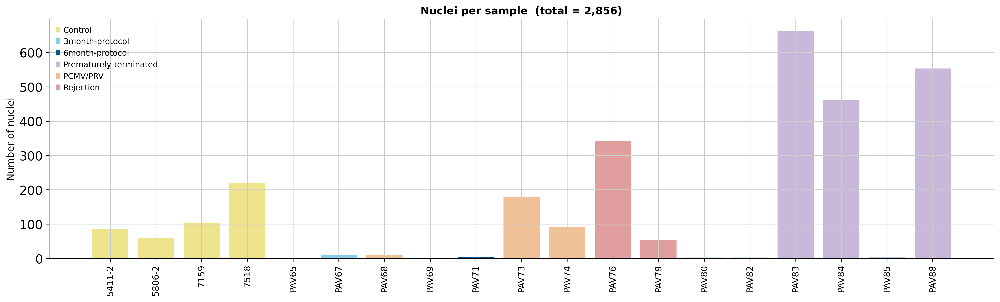

In [2]:
 
raw_annotated_mye_sus = sc.read ('/data/ag_reichart_lindberg/nhadizad/nastaran/projects/xeno/analysis/v1/cellstate_annotation/Mye_sus/v3/objects/Raw_annotated_Myeloids_sus_v3.h5ad')
adata = raw_annotated_mye_sus.copy()
 
print(f"Loaded: {adata.n_obs:,} nuclei  ×  {adata.n_vars:,} genes")
print(f"Conditions: {adata.obs['Condition'].value_counts().to_dict()}")
 
# Cell count bar plot per sample
sample_meta = adata.obs[["Sample_ID", "Condition"]].drop_duplicates().set_index("Sample_ID")
counts      = adata.obs["Sample_ID"].value_counts().sort_index()
bar_colors  = [COND_COLORS.get(sample_meta.loc[s, "Condition"], "grey") for s in counts.index]
 
fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(range(len(counts)), counts.values, color=bar_colors, edgecolor="white", linewidth=0.5)
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=90, fontsize=10)
ax.set_ylabel("Number of nuclei", fontsize=11)
ax.set_title(f"Nuclei per sample  (total = {adata.n_obs:,})", fontsize=12, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    handles=[Patch(facecolor=v, label=k) for k, v in COND_COLORS.items()],
    loc="upper left", frameon=False, fontsize=9
)
plt.tight_layout()
# plt.savefig(f"{OUTPUT_DIR}/01_cell_counts_per_sample.pdf", dpi=150, bbox_inches="tight")
plt.show()
# print("Saved: 01_cell_counts_per_sample")

